# CSE465 — Notebook 12: PVTv2-B0 + BiMamba + ASFF + AdaLoRA + RetinaNet + TADGNN

This notebook is the **Topology-Aware Dynamic Graph Neural Network (TADGNN) revision** of the submitted static-GBR stage.

## Correct initialization for the graph ablation

This revised Notebook 12 **does not train the detector from scratch**.

It starts from the trained AdaLoRA detector produced by Notebook 09:

`09_PVTv2B0_Mamba_ASFF_AdaLoRA_RetinaNet_Aug/weights/best.pt`

The complete transferred detector is loaded first:
- PVTv2-B0 backbone,
- trained AdaLoRA adapters,
- deep bidirectional Mamba,
- FPN,
- ASFF,
- RetinaNet classification/regression heads.

Those transferred parameters are then **frozen**. Only the newly added **TADGNN** parameters are optimized in Notebook 12.

The notebook refuses to begin training if:
1. the Notebook 09 `best.pt` source checkpoint is missing,
2. source checkpoint class names do not match,
3. any source state-dict key fails to map exactly,
4. any non-TADGNN parameter remains trainable, or
5. an epoch-0 validation pass with the TADGNN residual gate temporarily set to zero does not reproduce the source checkpoint validation score within tolerance.

## What makes the graph dynamic?

For each image:
1. RetinaNet produces classification logits for all anchors.
2. The top `K=128` anchors are selected as graph nodes.
3. Each node receives the corresponding ASFF/FPN feature and normalized anchor geometry.
4. Pairwise affinities combine learned feature similarity and learned geometric/topological bias.
5. Each graph layer selects its own top `k=6` neighbors from the learned affinity matrix.
6. Connectivity is recomputed after every graph layer.
7. A residual correction head refines selected classification logits:

\[
Z' = Z + \tanh(\alpha)\,\Delta Z_{\mathrm{TADGNN}}
\]

The box-regression path remains unchanged so this experiment isolates graph-based classification refinement.

## Revised graph ablation

- **No graph** — Notebook 09 AdaLoRA `best.pt`
- **Static GBR** — submitted-paper result
- **TADGNN** — Notebook 09 `best.pt` + newly trained TADGNN

All Notebook 12 outputs are written to:

`MyDrive/Study Materials /CSE465/12_PVTv2B0_Mamba_ASFF_AdaLoRA_TADGNN_RetinaNet_Aug/`

When `RESUME=False`, any previous Notebook 12 outputs are archived automatically before the corrected run starts.


## 1. Colab environment — one-time PyTorch compatibility setup

**Use a T4 GPU runtime.**

The first time this cell runs on a default PyTorch 2.11 Colab runtime, it will
install the official PyTorch 2.10 / torchvision 0.25 CUDA 12.8 stack and then
**intentionally restart the Python session**.

After Colab reconnects, run the notebook from the top again. The cell will then
detect the correct versions and continue without another restart.

In [1]:
import os
import sys
import time
import subprocess
from importlib import metadata

TARGET_TORCH = "2.10.0"
TARGET_TORCHVISION = "0.25.0"
TARGET_TORCHAUDIO = "2.10.0"

# GPU check without importing torch yet.
gpu_check = subprocess.run(
    ["nvidia-smi", "-L"],
    capture_output=True,
    text=True,
)

if gpu_check.returncode != 0:
    raise RuntimeError(
        "No NVIDIA GPU detected. In Colab choose "
        "Runtime > Change runtime type > T4 GPU, "
        "then run this cell again."
    )

print("GPU:")
print(gpu_check.stdout.strip())

try:
    installed_torch = metadata.version("torch")
except metadata.PackageNotFoundError:
    installed_torch = "not installed"

try:
    installed_tv = metadata.version("torchvision")
except metadata.PackageNotFoundError:
    installed_tv = "not installed"

print("\nCurrent package versions:")
print("torch      :", installed_torch)
print("torchvision:", installed_tv)

torch_ok = installed_torch.startswith(
    TARGET_TORCH
)

tv_ok = installed_tv.startswith(
    TARGET_TORCHVISION
)

if not (torch_ok and tv_ok):
    print(
        "\nInstalling the Mamba-compatible "
        "PyTorch 2.10 + CUDA 12.8 stack..."
    )

    start = time.perf_counter()

    subprocess.run(
        [
            sys.executable,
            "-m",
            "pip",
            "install",
            "-q",
            "--upgrade",
            f"torch=={TARGET_TORCH}",
            f"torchvision=={TARGET_TORCHVISION}",
            f"torchaudio=={TARGET_TORCHAUDIO}",
            "--index-url",
            "https://download.pytorch.org/whl/cu128",
        ],
        check=True,
    )

    print(
        f"✅ PyTorch stack installed in "
        f"{(time.perf_counter()-start)/60:.2f} min"
    )

    print(
        "\nThe session will restart now so the newly "
        "installed PyTorch libraries are loaded cleanly."
    )
    print(
        "After Colab reconnects, RUN THE NOTEBOOK "
        "FROM THE TOP ONE MORE TIME."
    )

    sys.stdout.flush()
    time.sleep(3)

    # Intentional kernel restart. Installed packages remain in the VM.
    os.kill(
        os.getpid(),
        9,
    )

print(
    "\n✅ Compatible PyTorch package versions already installed. "
    "No restart needed."
)

GPU:
GPU 0: Tesla T4 (UUID: GPU-502b7465-3723-41e1-1ccb-e6eb02df327b)

Current package versions:
torch      : 2.10.0+cu128
torchvision: 0.25.0+cu128

✅ Compatible PyTorch package versions already installed. No restart needed.


## 2. Install dependencies + exact prebuilt Mamba CUDA wheel

This cell deliberately installs a **specific wheel URL** instead of asking pip
to build Mamba from source.

The wheel filename is generated from:
- Python version
- CUDA major version
- PyTorch major/minor version
- C++11 ABI setting

If the expected wheel is unavailable, the cell fails immediately rather than
silently spending a long time compiling CUDA code.

In [2]:
import os
import sys
import time
import subprocess

# ------------------------------------------------------------
# Normal project dependencies
# ------------------------------------------------------------
print("Installing project dependencies...")

start = time.perf_counter()

subprocess.run(
    [
        sys.executable,
        "-m",
        "pip",
        "install",
        "-q",
        "setuptools==80.9.0",
        "wheel",
        "packaging",
        "ninja",
        "jedi>=0.16",
        "timm",
        "torchmetrics",
        "pycocotools",
        "einops",
        "peft==0.20.0",
    ],
    check=True,
)

print(
    f"✅ Project dependencies installed in "
    f"{(time.perf_counter()-start)/60:.2f} min"
)


# ------------------------------------------------------------
# Verify the pinned CUDA PyTorch stack
# ------------------------------------------------------------
import torch
import torchvision

print("\nEnvironment:")
print("Python      :", sys.version.split()[0])
print("Torch       :", torch.__version__)
print("Torchvision :", torchvision.__version__)
print("Torch CUDA  :", torch.version.cuda)
print("CUDA ready  :", torch.cuda.is_available())
print(
    "CXX11 ABI   :",
    torch._C._GLIBCXX_USE_CXX11_ABI,
)

if not torch.__version__.startswith(
    "2.10.0"
):
    raise RuntimeError(
        "PyTorch 2.10 is required for the prebuilt "
        "Mamba wheel used by this notebook. "
        "Rerun the previous environment cell."
    )

if not torchvision.__version__.startswith(
    "0.25.0"
):
    raise RuntimeError(
        "torchvision 0.25 is required with PyTorch 2.10."
    )

if not torch.cuda.is_available():
    raise RuntimeError(
        "CUDA is unavailable. Switch Colab to T4 GPU."
    )

if torch.version.cuda is None:
    raise RuntimeError(
        "CUDA-enabled PyTorch was not installed."
    )


# ------------------------------------------------------------
# Exact Mamba wheel URL
# ------------------------------------------------------------
MAMBA_VERSION = "2.3.2.post1"

py_tag = (
    f"cp{sys.version_info.major}"
    f"{sys.version_info.minor}"
)

torch_base = (
    torch.__version__
    .split("+")[0]
)

torch_mm = ".".join(
    torch_base.split(".")[:2]
)

cuda_major = (
    torch.version.cuda
    .split(".")[0]
)

abi = str(
    torch._C._GLIBCXX_USE_CXX11_ABI
).upper()

wheel_name = (
    f"mamba_ssm-{MAMBA_VERSION}"
    f"+cu{cuda_major}"
    f"torch{torch_mm}"
    f"cxx11abi{abi}"
    f"-{py_tag}-{py_tag}"
    f"-linux_x86_64.whl"
)

wheel_url = (
    "https://github.com/state-spaces/mamba/releases/download/"
    f"v{MAMBA_VERSION}/"
    f"{wheel_name}"
)

print("\nInstalling exact prebuilt Mamba CUDA wheel:")
print(wheel_name)

start = time.perf_counter()

try:
    subprocess.run(
        [
            sys.executable,
            "-m",
            "pip",
            "install",
            "-q",
            wheel_url,
        ],
        check=True,
    )
except subprocess.CalledProcessError as exc:
    raise RuntimeError(
        "The exact prebuilt Mamba wheel could not be installed. "
        "This notebook intentionally does NOT fall back to slow "
        "source compilation.\n\nExpected wheel:\n"
        f"{wheel_url}\n\n"
        "Do not continue to training."
    ) from exc

print(
    f"✅ Prebuilt Mamba wheel installed in "
    f"{(time.perf_counter()-start)/60:.2f} min"
)


# ------------------------------------------------------------
# CUDA extension + forward/backward smoke test
# ------------------------------------------------------------
try:
    import selective_scan_cuda
    from mamba_ssm import Mamba
except Exception as exc:
    raise RuntimeError(
        "Mamba installed, but the CUDA selective-scan "
        "extension is not available."
    ) from exc

print(
    "✅ selective_scan_cuda import passed"
)

smoke_model = Mamba(
    d_model=256,
    d_state=16,
    d_conv=4,
    expand=2,
).cuda()

smoke_x = torch.randn(
    1,
    400,
    256,
    device="cuda",
    requires_grad=True,
)

smoke_y = smoke_model(
    smoke_x
)

if smoke_y.shape != smoke_x.shape:
    raise RuntimeError(
        "Unexpected Mamba output shape."
    )

if not torch.isfinite(
    smoke_y
).all():
    raise RuntimeError(
        "Non-finite values found in Mamba smoke test."
    )

smoke_y.mean().backward()

print(
    "✅ Mamba CUDA forward + backward test PASSED"
)
print(
    "Input/output:",
    tuple(smoke_x.shape),
)

del smoke_model
del smoke_x
del smoke_y

import gc
gc.collect()
torch.cuda.empty_cache()

import peft
print("PEFT        :", peft.__version__)
if peft.__version__ != "0.20.0":
    raise RuntimeError("This notebook expects peft==0.20.0.")

print(
    "\n✅ Environment is ready for the Mamba + AdaLoRA experiment."
)

Installing project dependencies...
✅ Project dependencies installed in 0.30 min

Environment:
Python      : 3.13.15
Torch       : 2.10.0+cu128
Torchvision : 0.25.0+cu128
Torch CUDA  : 12.8
CUDA ready  : True
CXX11 ABI   : True

Installing exact prebuilt Mamba CUDA wheel:
mamba_ssm-2.3.2.post1+cu12torch2.10cxx11abiTRUE-cp313-cp313-linux_x86_64.whl
✅ Prebuilt Mamba wheel installed in 0.65 min
✅ selective_scan_cuda import passed
✅ Mamba CUDA forward + backward test PASSED
Input/output: (1, 400, 256)
PEFT        : 0.20.0

✅ Environment is ready for the Mamba + AdaLoRA experiment.


## 3. Mount Google Drive

In [3]:
from google.colab import drive

drive.mount(
    "/content/drive"
)

Mounted at /content/drive


## 4. Imports and reproducibility

In [4]:
import os
import math
import re
import gc
import cv2
import time
import yaml
import random
import shutil
import warnings
import zipfile

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from collections import OrderedDict, defaultdict

import torch
import torchvision
import timm

from torch import nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

from torchvision.models.detection.retinanet import RetinaNet
from torchvision.transforms import v2
from torchvision import tv_tensors
from torchvision.ops import FeaturePyramidNetwork, box_iou
from torchvision.ops.feature_pyramid_network import LastLevelP6P7

from torchmetrics.detection.mean_ap import MeanAveragePrecision
from mamba_ssm import Mamba
from peft import AdaLoraConfig, get_peft_model
import peft

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

torch.backends.cudnn.benchmark = False
torch.backends.cudnn.deterministic = True

DEVICE = torch.device(
    "cuda"
)

if not torch.cuda.is_available():
    raise RuntimeError(
        "GPU is required for this experiment."
    )

print("PyTorch:", torch.__version__)
print("Torchvision:", torchvision.__version__)
print("timm:", timm.__version__)
print("GPU:", torch.cuda.get_device_name(0))
print("Mamba import: OK")
print("PEFT:", peft.__version__)

PyTorch: 2.10.0+cu128
Torchvision: 0.25.0+cu128
timm: 1.0.28
GPU: Tesla T4
Mamba import: OK
PEFT: 0.20.0


## 5. Drive folders — Notebook 12 output initialized from Notebook 09 AdaLoRA `best.pt`


In [5]:
CSE_ROOT = Path(
    "/content/drive/MyDrive/Study Materials /CSE465"
)

DATA_ZIP = CSE_ROOT / "Prepared Dataset.zip"

# ------------------------------------------------------------
# REQUIRED SOURCE: Notebook 09 trained AdaLoRA detector.
# Notebook 12 must never silently fall back to scratch training.
# ------------------------------------------------------------
SOURCE_EXP_ROOT = (
    CSE_ROOT
    / "09_PVTv2B0_Mamba_ASFF_AdaLoRA_RetinaNet_Aug"
)

SOURCE_BEST_PT = (
    SOURCE_EXP_ROOT
    / "weights"
    / "best.pt"
)

EXP_ROOT = (
    CSE_ROOT
    / "12_PVTv2B0_Mamba_ASFF_AdaLoRA_TADGNN_RetinaNet_Aug"
)

WEIGHTS_DIR = EXP_ROOT / "weights"
METRICS_DIR = EXP_ROOT / "metrics"
PLOTS_DIR = EXP_ROOT / "plots"
PREDICTIONS_DIR = EXP_ROOT / "predictions"
CONFIG_DIR = EXP_ROOT / "config"

for folder in [
    EXP_ROOT,
    WEIGHTS_DIR,
    METRICS_DIR,
    PLOTS_DIR,
    PREDICTIONS_DIR,
    CONFIG_DIR,
]:
    folder.mkdir(
        parents=True,
        exist_ok=True,
    )

BEST_PT = WEIGHTS_DIR / "best.pt"
LAST_PT = WEIGHTS_DIR / "last.pt"

assert DATA_ZIP.exists(), (
    f"Dataset ZIP not found: {DATA_ZIP}"
)

if not SOURCE_BEST_PT.exists():
    raise FileNotFoundError(
        "Notebook 09 AdaLoRA best.pt is REQUIRED. "
        "Notebook 12 will not train from scratch.\n"
        f"Expected source checkpoint:\n{SOURCE_BEST_PT}"
    )

print("Dataset:", DATA_ZIP)
print("Source AdaLoRA checkpoint:", SOURCE_BEST_PT)
print("Notebook 12 experiment:", EXP_ROOT)
print(
    "Training mode: transfer Notebook 09 best.pt, "
    "freeze transferred detector, train TADGNN only"
)


Dataset: /content/drive/MyDrive/Study Materials /CSE465/Prepared Dataset.zip
Source AdaLoRA checkpoint: /content/drive/MyDrive/Study Materials /CSE465/09_PVTv2B0_Mamba_ASFF_AdaLoRA_RetinaNet_Aug/weights/best.pt
Notebook 12 experiment: /content/drive/MyDrive/Study Materials /CSE465/12_PVTv2B0_Mamba_ASFF_AdaLoRA_TADGNN_RetinaNet_Aug
Training mode: transfer Notebook 09 best.pt, freeze transferred detector, train TADGNN only


### Drive storage safety check

This cell performs a temporary **128 MB real write test** inside the Notebook 12
experiment folder before training.

In [6]:
DRIVE_TEST_MB = 128

test_file = (
    EXP_ROOT
    / "_drive_write_test.bin"
)

print(
    f"Testing Google Drive write capacity "
    f"with {DRIVE_TEST_MB} MB..."
)

try:
    chunk = b"\0" * (
        1024 * 1024
    )

    with open(
        test_file,
        "wb",
    ) as f:
        for _ in range(
            DRIVE_TEST_MB
        ):
            f.write(chunk)

        f.flush()
        os.fsync(
            f.fileno()
        )

    written_mb = (
        test_file.stat().st_size
        / 1024**2
    )

    if written_mb < DRIVE_TEST_MB:
        raise RuntimeError(
            "Drive write test produced an incomplete file."
        )

    print(
        f"✅ Drive write test passed "
        f"({written_mb:.0f} MB)."
    )

finally:
    if test_file.exists():
        test_file.unlink()

print(
    "Temporary test file deleted."
)

Testing Google Drive write capacity with 128 MB...
✅ Drive write test passed (128 MB).
Temporary test file deleted.


## 6. Extract prepared dataset locally

In [7]:
LOCAL_ROOT = Path("/content/CSE465_dataset")

if LOCAL_ROOT.exists():
    shutil.rmtree(LOCAL_ROOT)

LOCAL_ROOT.mkdir(parents=True, exist_ok=True)

with zipfile.ZipFile(DATA_ZIP, "r") as z:
    z.extractall(LOCAL_ROOT)

DATASET_DIR = LOCAL_ROOT / "Prepared Dataset"
DATA_YAML = DATASET_DIR / "data.yaml"

assert DATASET_DIR.exists()
assert DATA_YAML.exists()

print("Dataset extracted to:", DATASET_DIR)

Dataset extracted to: /content/CSE465_dataset/Prepared Dataset


## 7. Read dataset configuration

In [8]:
with open(DATA_YAML, "r") as f:
    data_config = yaml.safe_load(f)

CLASS_NAMES = data_config["names"]
NUM_CLASSES = len(CLASS_NAMES)

print("Classes:", CLASS_NAMES)
print("Number of detection classes:", NUM_CLASSES)

for split in ["train", "val", "test"]:
    n_img = len(list((DATASET_DIR / "images" / split).glob("*")))
    n_lbl = len(list((DATASET_DIR / "labels" / split).glob("*.txt")))
    print(f"{split:5s}: {n_img} images | {n_lbl} labels")

Classes: ['finger', 'crack', 'black_core', 'thick_line', 'horizontal_dislocation', 'short_circuit', 'vertical_dislocation', 'star_crack', 'printing_error']
Number of detection classes: 9
train: 4418 images | 4418 labels
val  : 947 images | 947 labels
test : 949 images | 949 labels


## 8. Notebook 12 configuration — initialize from Notebook 09 AdaLoRA best.pt


In [9]:
IMAGE_SIZE = 640

BATCH_SIZE = 8
ACCUM_STEPS = 2
EFFECTIVE_BATCH = (
    BATCH_SIZE
    * ACCUM_STEPS
)

MAX_EPOCHS = 25
PATIENCE = 25
NUM_WORKERS = 2

WEIGHT_DECAY = 0.05
GRAD_CLIP = 1.0
MIN_LR = 1e-6

# ------------------------------------------------------------
# Correct Notebook 12 optimization:
# - source detector comes from Notebook 09 best.pt
# - ALL transferred detector parameters stay frozen
# - ONLY TADGNN is optimized
# ------------------------------------------------------------
LR_WARMUP_EPOCHS = 2
LR_TADGNN = 3e-4

# These values are needed only to reconstruct the exact PEFT
# AdaLoRA module structure before loading Notebook 09 state_dict.
# AdaLoRA itself is NOT updated in Notebook 12.
ADALORA_INIT_R = 12
ADALORA_TARGET_R = 8
ADALORA_ALPHA = 32
ADALORA_DROPOUT = 0.0

ADALORA_INIT_EPOCHS = 2
ADALORA_FINAL_EPOCHS = 5
ADALORA_DELTA_T = 25

ADALORA_BETA1 = 0.85
ADALORA_BETA2 = 0.85
ADALORA_ORTH_REG_WEIGHT = 0.10

AMP = True

CONF_THRESHOLD = 0.25
MATCH_IOU_THRESHOLD = 0.50

# Maximum accepted absolute difference between the source checkpoint's
# stored validation mAP@50-95 and the epoch-0 source-reproduction pass.
SOURCE_VAL_TOLERANCE = 0.005

# False for a new corrected Notebook 12 run.
# True only to resume THIS Notebook 12 from its own last.pt.
RESUME = True

# ------------------------------------------------------------
# EXACT SAME augmentation recipe as Notebooks 05/06/07/09.
# Augmentation is applied only to the TADGNN training images.
# ------------------------------------------------------------
AUGMENTATION = {
    "brightness": 0.15,
    "brightness_p": 0.50,

    "contrast": 0.10,
    "contrast_p": 0.50,

    "gaussian_blur_p": 0.10,
    "gaussian_blur_kernel": 3,
    "gaussian_blur_sigma_min": 0.10,
    "gaussian_blur_sigma_max": 0.80,

    "gaussian_noise_p": 0.15,
    "gaussian_noise_std": 0.01,

    "fliplr": 0.50,
    "flipud": 0.50,

    "degrees": 0.0,
    "translate": 0.0,
    "scale": 0.0,
    "shear": 0.0,

    "mosaic": 0.0,
    "mixup": 0.0,
    "cutmix": 0.0,
    "copy_paste": 0.0,
    "erasing": 0.0,
}

MAMBA_CONFIG = {
    "placement":
        "deepest PVT feature before FPN",

    "d_model":
        256,

    "d_state":
        16,

    "d_conv":
        4,

    "expand":
        2,

    "bidirectional":
        True,

    "shared_forward_reverse_weights":
        True,

    "notebook12_status":
        "loaded from Notebook 09 best.pt and frozen",
}

ASFF_CONFIG = {
    "placement":
        "after FPN and before RetinaNet",

    "fused_levels":
        ["P3", "P4", "P5"],

    "unchanged_levels":
        ["P6", "P7"],

    "channels":
        256,

    "compress_channels":
        8,

    "spatial_weighting":
        "softmax over P3/P4/P5 at every spatial position",

    "residual_gate_init":
        0.1,

    "notebook12_status":
        "loaded from Notebook 09 best.pt and frozen",
}

# ------------------------------------------------------------
# Topology-Aware Dynamic Graph Neural Network (TADGNN)
# ------------------------------------------------------------
TADGNN_TOP_K = 128
TADGNN_K_NEIGHBORS = 6
TADGNN_NUM_LAYERS = 2
TADGNN_NUM_HEADS = 4
TADGNN_HIDDEN_DIM = 256
TADGNN_GEOM_HIDDEN = 32
TADGNN_GATE_INIT = 0.1
TADGNN_CORRECTION_INIT_STD = 1e-3
TADGNN_DROPOUT = 0.0

TADGNN_CONFIG = {
    "placement":
        "after RetinaNet head and before loss/NMS",

    "node_source":
        "top-scoring RetinaNet anchors",

    "top_k":
        TADGNN_TOP_K,

    "node_feature_source":
        "corresponding ASFF/FPN spatial feature + normalized anchor geometry",

    "dynamic_topology":
        True,

    "topology_recomputed_each_layer":
        True,

    "edge_affinity":
        "multi-head learned feature affinity + learned relative-geometry bias",

    "relative_geometry":
        ["dx", "dy", "log_width_ratio", "log_height_ratio", "anchor_iou"],

    "k_neighbors":
        TADGNN_K_NEIGHBORS,

    "num_layers":
        TADGNN_NUM_LAYERS,

    "num_heads":
        TADGNN_NUM_HEADS,

    "hidden_dim":
        TADGNN_HIDDEN_DIM,

    "geometry_hidden_dim":
        TADGNN_GEOM_HIDDEN,

    "residual_gate_init":
        TADGNN_GATE_INIT,

    "correction_head_init_std":
        TADGNN_CORRECTION_INIT_STD,

    "dropout":
        TADGNN_DROPOUT,

    "bbox_refinement":
        False,

    "classification_refinement":
        True,
}

ADALORA_CONFIG = {
    "implementation":
        "Hugging Face PEFT AdaLoRA",

    "peft_version":
        "0.20.0",

    "placement":
        "PVTv2 attention and MLP linear layers",

    "target_modules": [
        "attn.q",
        "attn.kv",
        "attn.proj",
        "mlp.fc1",
        "mlp.fc2",
    ],

    "init_r":
        ADALORA_INIT_R,

    "target_r":
        ADALORA_TARGET_R,

    "lora_alpha":
        ADALORA_ALPHA,

    "lora_dropout":
        ADALORA_DROPOUT,

    "init_epochs":
        ADALORA_INIT_EPOCHS,

    "final_epochs":
        ADALORA_FINAL_EPOCHS,

    "deltaT":
        ADALORA_DELTA_T,

    "beta1":
        ADALORA_BETA1,

    "beta2":
        ADALORA_BETA2,

    "orth_reg_weight":
        ADALORA_ORTH_REG_WEIGHT,

    "notebook12_status":
        "loaded from Notebook 09 best.pt and frozen",

    "dynamic_rank_allocation_in_notebook12":
        False,
}

training_config = {
    "model":
        "PVTv2-B0 + BiMamba + FPN + ASFF + AdaLoRA + RetinaNet + TADGNN",

    "experiment":
        "A4_Aug_Mamba_ASFF_AdaLoRA_TADGNN_From_AdaLoRA_BestPT",

    "source_checkpoint":
        str(SOURCE_BEST_PT),

    "initialization":
        "exact Notebook 09 AdaLoRA best.pt for the complete detector; "
        "new TADGNN initialized separately",

    "optimization_scope":
        "TADGNN only; transferred detector frozen",

    "image_size":
        IMAGE_SIZE,

    "physical_batch_size":
        BATCH_SIZE,

    "gradient_accumulation":
        ACCUM_STEPS,

    "effective_batch_size":
        EFFECTIVE_BATCH,

    "max_epochs":
        MAX_EPOCHS,

    "patience":
        PATIENCE,

    "lr_warmup_epochs":
        LR_WARMUP_EPOCHS,

    "lr_tadgnn":
        LR_TADGNN,

    "min_lr":
        MIN_LR,

    "weight_decay":
        WEIGHT_DECAY,

    "source_val_tolerance":
        SOURCE_VAL_TOLERANCE,

    "seed":
        SEED,

    "augmentation":
        AUGMENTATION,

    "augmentation_scope":
        "train only, on-the-fly",

    "mamba":
        MAMBA_CONFIG,

    "asff":
        ASFF_CONFIG,

    "tadgnn":
        TADGNN_CONFIG,

    "adalora":
        ADALORA_CONFIG,

    "detections_per_image":
        100,
}

# Preserve the previous Notebook 12 run instead of overwriting it.
if not RESUME:
    existing_run = (
        BEST_PT.exists()
        or LAST_PT.exists()
        or (
            METRICS_DIR
            / "training_history.csv"
        ).exists()
    )

    if existing_run:
        archive_stamp = time.strftime(
            "%Y%m%d_%H%M%S"
        )

        archive_root = (
            EXP_ROOT
            / "archive"
            / archive_stamp
        )

        archive_root.mkdir(
            parents=True,
            exist_ok=True,
        )

        for folder in [
            WEIGHTS_DIR,
            METRICS_DIR,
            PLOTS_DIR,
            PREDICTIONS_DIR,
            CONFIG_DIR,
        ]:
            if (
                folder.exists()
                and any(folder.iterdir())
            ):
                shutil.move(
                    str(folder),
                    str(
                        archive_root
                        / folder.name
                    ),
                )

            folder.mkdir(
                parents=True,
                exist_ok=True,
            )

        print(
            "Archived previous Notebook 12 outputs to:",
            archive_root,
        )

with open(
    CONFIG_DIR
    / "training_config.yaml",
    "w",
) as f:
    yaml.safe_dump(
        training_config,
        f,
        sort_keys=False,
    )

print(training_config)


{'model': 'PVTv2-B0 + BiMamba + FPN + ASFF + AdaLoRA + RetinaNet + TADGNN', 'experiment': 'A4_Aug_Mamba_ASFF_AdaLoRA_TADGNN_From_AdaLoRA_BestPT', 'source_checkpoint': '/content/drive/MyDrive/Study Materials /CSE465/09_PVTv2B0_Mamba_ASFF_AdaLoRA_RetinaNet_Aug/weights/best.pt', 'initialization': 'exact Notebook 09 AdaLoRA best.pt for the complete detector; new TADGNN initialized separately', 'optimization_scope': 'TADGNN only; transferred detector frozen', 'image_size': 640, 'physical_batch_size': 8, 'gradient_accumulation': 2, 'effective_batch_size': 16, 'max_epochs': 25, 'patience': 25, 'lr_warmup_epochs': 2, 'lr_tadgnn': 0.0003, 'min_lr': 1e-06, 'weight_decay': 0.05, 'source_val_tolerance': 0.005, 'seed': 42, 'augmentation': {'brightness': 0.15, 'brightness_p': 0.5, 'contrast': 0.1, 'contrast_p': 0.5, 'gaussian_blur_p': 0.1, 'gaussian_blur_kernel': 3, 'gaussian_blur_sigma_min': 0.1, 'gaussian_blur_sigma_max': 0.8, 'gaussian_noise_p': 0.15, 'gaussian_noise_std': 0.01, 'fliplr': 0.5, 'f

## 9. Dataset class — same augmentation as Notebooks 05/06/07/09


In [10]:
IMAGE_EXTENSIONS = {
    ".jpg", ".jpeg", ".png",
    ".bmp", ".tif", ".tiff",
}


def letterbox_image(
    image,
    boxes,
    size=640,
    fill=114,
):
    h, w = image.shape[:2]

    scale = min(
        size / w,
        size / h,
    )

    new_w = int(
        round(w * scale)
    )

    new_h = int(
        round(h * scale)
    )

    resized = cv2.resize(
        image,
        (new_w, new_h),
        interpolation=cv2.INTER_LINEAR,
    )

    pad_x = (
        size - new_w
    ) // 2

    pad_y = (
        size - new_h
    ) // 2

    canvas = np.full(
        (size, size, 3),
        fill,
        dtype=np.uint8,
    )

    canvas[
        pad_y:pad_y + new_h,
        pad_x:pad_x + new_w,
    ] = resized

    boxes = np.asarray(
        boxes,
        dtype=np.float32,
    ).reshape(-1, 4)

    if len(boxes):
        boxes = boxes.copy()

        boxes[:, [0, 2]] = (
            boxes[:, [0, 2]]
            * scale
            + pad_x
        )

        boxes[:, [1, 3]] = (
            boxes[:, [1, 3]]
            * scale
            + pad_y
        )

    return canvas, boxes


train_transform = v2.Compose([
    v2.RandomApply(
        [
            v2.ColorJitter(
                brightness=AUGMENTATION["brightness"],
                contrast=0.0,
                saturation=0.0,
                hue=0.0,
            )
        ],
        p=AUGMENTATION["brightness_p"],
    ),

    v2.RandomApply(
        [
            v2.ColorJitter(
                brightness=0.0,
                contrast=AUGMENTATION["contrast"],
                saturation=0.0,
                hue=0.0,
            )
        ],
        p=AUGMENTATION["contrast_p"],
    ),

    v2.RandomApply(
        [
            v2.GaussianBlur(
                kernel_size=AUGMENTATION[
                    "gaussian_blur_kernel"
                ],
                sigma=(
                    AUGMENTATION[
                        "gaussian_blur_sigma_min"
                    ],
                    AUGMENTATION[
                        "gaussian_blur_sigma_max"
                    ],
                ),
            )
        ],
        p=AUGMENTATION["gaussian_blur_p"],
    ),

    v2.RandomHorizontalFlip(
        p=AUGMENTATION["fliplr"]
    ),

    v2.RandomVerticalFlip(
        p=AUGMENTATION["flipud"]
    ),
])


class PVDetectionDataset(Dataset):
    def __init__(
        self,
        dataset_dir,
        split,
        image_size=640,
        augment=False,
    ):
        self.image_dir = (
            Path(dataset_dir)
            / "images"
            / split
        )

        self.label_dir = (
            Path(dataset_dir)
            / "labels"
            / split
        )

        self.split = split
        self.image_size = image_size
        self.augment = augment

        self.images = sorted(
            p
            for p in self.image_dir.iterdir()
            if p.suffix.lower()
            in IMAGE_EXTENSIONS
        )

    def __len__(self):
        return len(self.images)

    def _load_raw(self, idx):
        image_path = self.images[idx]

        label_path = (
            self.label_dir
            / f"{image_path.stem}.txt"
        )

        image = cv2.imread(
            str(image_path)
        )

        if image is None:
            raise RuntimeError(
                f"Could not read: {image_path}"
            )

        image = cv2.cvtColor(
            image,
            cv2.COLOR_BGR2RGB,
        )

        h, w = image.shape[:2]

        boxes = []
        labels = []

        if label_path.exists():
            text = (
                label_path
                .read_text()
                .strip()
            )

            if text:
                for line in text.splitlines():
                    (
                        cls_id,
                        xc,
                        yc,
                        bw,
                        bh,
                    ) = map(
                        float,
                        line.split(),
                    )

                    x1 = (
                        xc - bw / 2
                    ) * w

                    y1 = (
                        yc - bh / 2
                    ) * h

                    x2 = (
                        xc + bw / 2
                    ) * w

                    y2 = (
                        yc + bh / 2
                    ) * h

                    boxes.append(
                        [x1, y1, x2, y2]
                    )

                    labels.append(
                        int(cls_id)
                    )

        boxes = np.asarray(
            boxes,
            dtype=np.float32,
        ).reshape(-1, 4)

        labels = np.asarray(
            labels,
            dtype=np.int64,
        ).reshape(-1)

        return (
            image,
            boxes,
            labels,
            str(image_path),
        )

    def __getitem__(self, idx):
        (
            image,
            boxes,
            labels,
            image_path,
        ) = self._load_raw(idx)

        image, boxes = letterbox_image(
            image,
            boxes,
            size=self.image_size,
        )

        image = tv_tensors.Image(
            torch.from_numpy(
                np.ascontiguousarray(
                    image
                )
            ).permute(2, 0, 1)
        )

        boxes = tv_tensors.BoundingBoxes(
            torch.as_tensor(
                boxes,
                dtype=torch.float32,
            ).reshape(-1, 4),
            format="XYXY",
            canvas_size=(
                self.image_size,
                self.image_size,
            ),
        )

        target = {
            "boxes": boxes,
            "labels": torch.as_tensor(
                labels,
                dtype=torch.int64,
            ),
        }

        original_box_count = len(
            target["boxes"]
        )

        if self.augment:
            image, target = train_transform(
                image,
                target,
            )

        image = (
            image
            .as_subclass(torch.Tensor)
            .to(torch.float32)
            / 255.0
        )

        if (
            self.augment
            and random.random()
            < AUGMENTATION["gaussian_noise_p"]
        ):
            image = torch.clamp(
                image
                + torch.randn_like(image)
                * AUGMENTATION[
                    "gaussian_noise_std"
                ],
                0.0,
                1.0,
            )

        boxes_out = (
            target["boxes"]
            .as_subclass(torch.Tensor)
            .to(torch.float32)
        )

        labels_out = (
            target["labels"]
            .to(torch.int64)
        )

        if len(boxes_out) != original_box_count:
            raise RuntimeError(
                f"Unexpected box-count change: "
                f"{image_path}"
            )

        if len(boxes_out):
            if not torch.isfinite(
                boxes_out
            ).all():
                raise RuntimeError(
                    f"Non-finite box: "
                    f"{image_path}"
                )

            if not (
                (
                    boxes_out[:, 2]
                    > boxes_out[:, 0]
                ).all()
                and (
                    boxes_out[:, 3]
                    > boxes_out[:, 1]
                ).all()
            ):
                raise RuntimeError(
                    f"Invalid box: "
                    f"{image_path}"
                )

        target_out = {
            "boxes": boxes_out,
            "labels": labels_out,
            "image_id": torch.tensor(
                [idx],
                dtype=torch.int64,
            ),
        }

        return (
            image,
            target_out,
            image_path,
        )


def collate_fn(batch):
    images, targets, paths = zip(*batch)

    return (
        list(images),
        list(targets),
        list(paths),
    )


def seed_worker(worker_id):
    worker_seed = (
        torch.initial_seed()
        % 2**32
    )

    np.random.seed(worker_seed)
    random.seed(worker_seed)


loader_generator = torch.Generator()
loader_generator.manual_seed(SEED)


train_dataset = PVDetectionDataset(
    DATASET_DIR,
    "train",
    IMAGE_SIZE,
    augment=True,
)

val_dataset = PVDetectionDataset(
    DATASET_DIR,
    "val",
    IMAGE_SIZE,
    augment=False,
)

# Unaugmented copy of the training split, used only to measure
# training mAP@50-95 per epoch (kept separate from train_dataset
# so the mAP curve is not distorted by on-the-fly augmentation).
train_eval_dataset = PVDetectionDataset(
    DATASET_DIR,
    "train",
    IMAGE_SIZE,
    augment=False,
)

test_dataset = PVDetectionDataset(
    DATASET_DIR,
    "test",
    IMAGE_SIZE,
    augment=False,
)


train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=True,
    collate_fn=collate_fn,
    worker_init_fn=seed_worker,
    generator=loader_generator,
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=True,
    collate_fn=collate_fn,
    worker_init_fn=seed_worker,
)

train_eval_loader = DataLoader(
    train_eval_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=True,
    collate_fn=collate_fn,
    worker_init_fn=seed_worker,
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=True,
    collate_fn=collate_fn,
    worker_init_fn=seed_worker,
)

print(
    "Train:", len(train_dataset),
    "(augmentation ON)"
)

print(
    "Val  :", len(val_dataset),
    "(augmentation OFF)"
)

print(
    "Train (eval copy):", len(train_eval_dataset),
    "(augmentation OFF, used for training mAP curve)"
)

print(
    "Test :", len(test_dataset),
    "(augmentation OFF)"
)

print(
    "Effective batch:",
    EFFECTIVE_BATCH
)

Train: 4418 (augmentation ON)
Val  : 947 (augmentation OFF)
Train (eval copy): 4418 (augmentation OFF, used for training mAP curve)
Test : 949 (augmentation OFF)
Effective batch: 16


### 8.1 Mandatory augmentation preflight

This configuration does not crop or geometrically deform boxes, so the
preflight requires **100% box-count retention**.

It checks 1,000 random training samples before the long run.

AUGMENTATION PREFLIGHT
Samples checked: 1000
Invalid samples: 0

Class-wise annotation retention:
finger                   : 323/323 (100.0%)
crack                    : 207/207 (100.0%)
black_core               : 166/166 (100.0%)
thick_line               : 205/205 (100.0%)
horizontal_dislocation   : 362/362 (100.0%)
short_circuit            : 128/128 (100.0%)
vertical_dislocation     : 72/72 (100.0%)
star_crack               : 42/42 (100.0%)
printing_error           : 16/16 (100.0%)

Preflight PASSED.


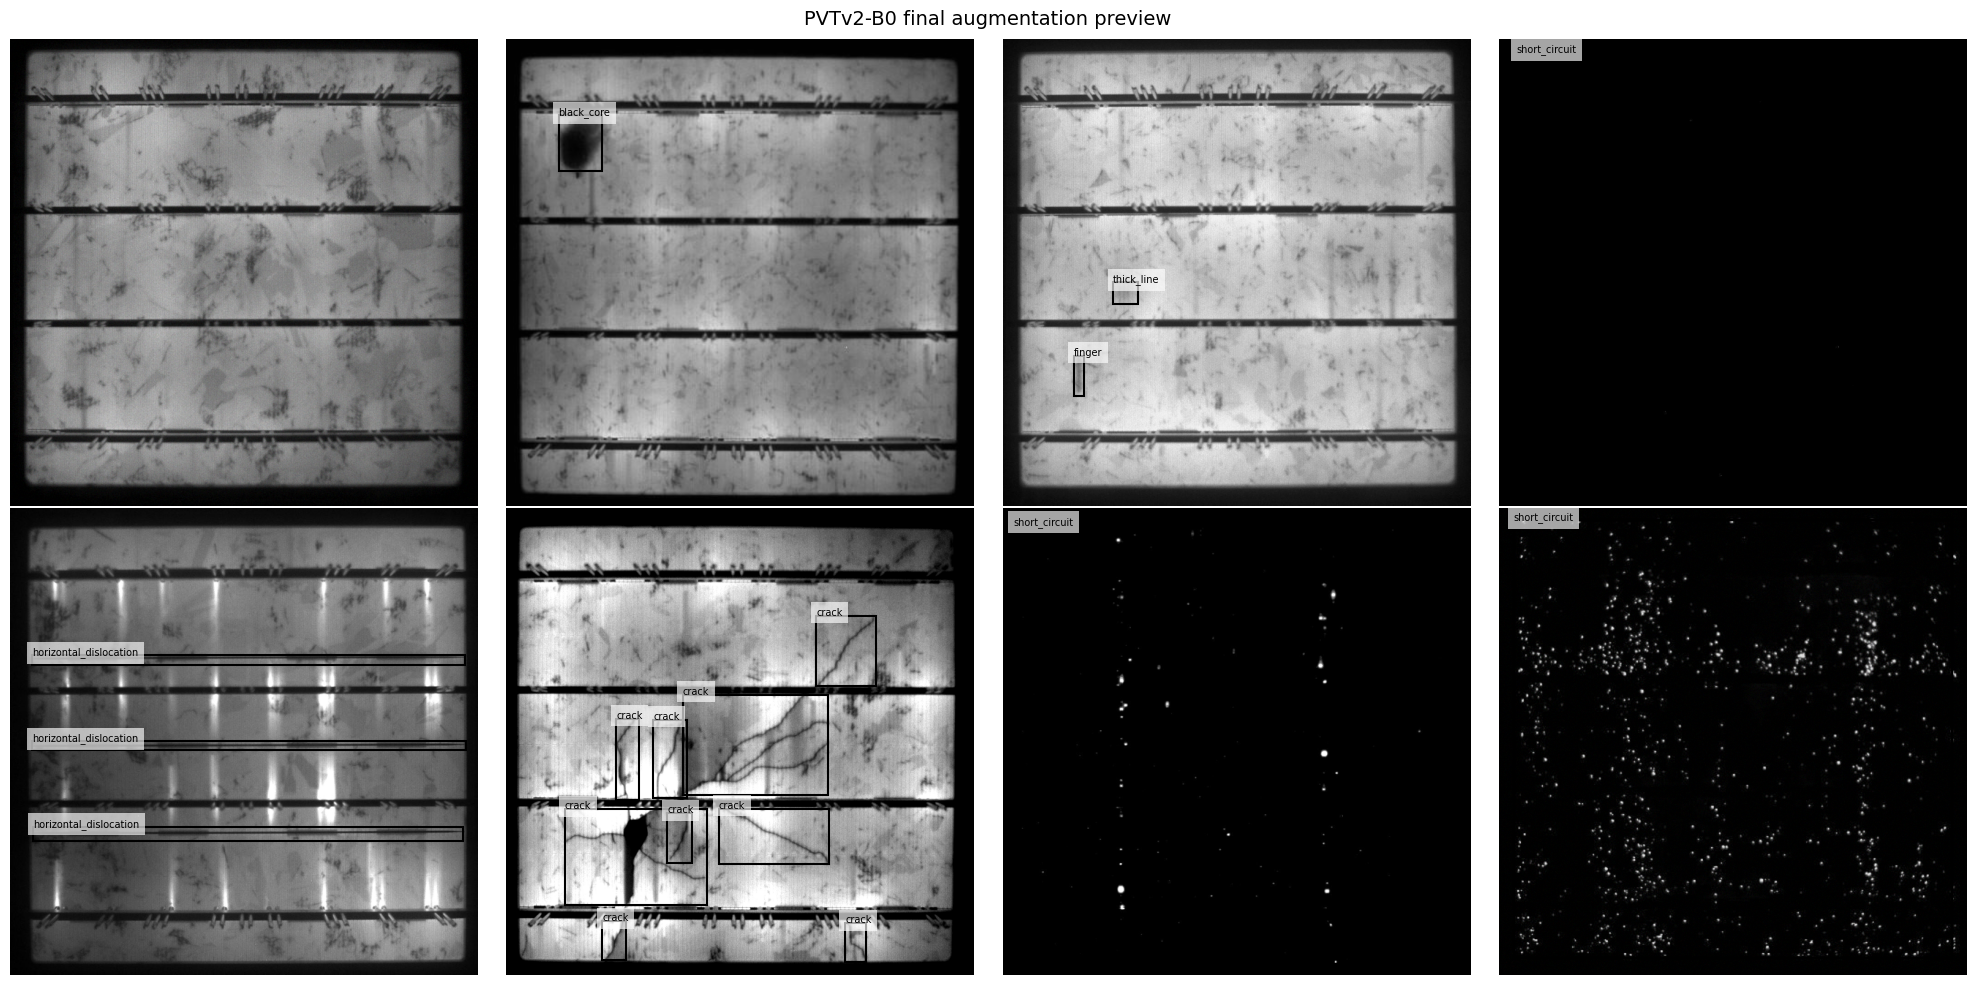

RNGs reset after preflight.


In [11]:
from matplotlib.patches import Rectangle

def augmentation_preflight(
    dataset,
    sample_count=1000,
):
    selector = random.Random(SEED)

    indices = [
        selector.randrange(
            len(dataset)
        )
        for _ in range(sample_count)
    ]

    raw_counts = np.zeros(
        NUM_CLASSES,
        dtype=np.int64,
    )

    aug_counts = np.zeros(
        NUM_CLASSES,
        dtype=np.int64,
    )

    invalid = 0

    for idx in indices:
        (
            _,
            raw_boxes,
            raw_labels,
            _,
        ) = dataset._load_raw(idx)

        raw_counts += np.bincount(
            raw_labels,
            minlength=NUM_CLASSES,
        )

        image, target, _ = dataset[idx]

        boxes = (
            target["boxes"]
            .cpu()
            .numpy()
        )

        labels = (
            target["labels"]
            .cpu()
            .numpy()
        )

        aug_counts += np.bincount(
            labels,
            minlength=NUM_CLASSES,
        )

        if len(boxes) != len(raw_boxes):
            invalid += 1
            continue

        if len(boxes):
            if not np.isfinite(
                boxes
            ).all():
                invalid += 1
                continue

            if not (
                (
                    boxes[:, 2]
                    > boxes[:, 0]
                ).all()
                and (
                    boxes[:, 3]
                    > boxes[:, 1]
                ).all()
            ):
                invalid += 1

    print("=" * 70)
    print("AUGMENTATION PREFLIGHT")
    print("=" * 70)
    print(
        "Samples checked:",
        sample_count,
    )
    print(
        "Invalid samples:",
        invalid,
    )

    if invalid != 0:
        raise RuntimeError(
            "Augmentation preflight failed. "
            "Do NOT start training."
        )

    print(
        "\nClass-wise annotation retention:"
    )

    for cls_id, name in enumerate(
        CLASS_NAMES
    ):
        raw_n = int(
            raw_counts[cls_id]
        )

        aug_n = int(
            aug_counts[cls_id]
        )

        if raw_n == 0:
            print(
                f"{name:25s}: "
                "not sampled"
            )
            continue

        print(
            f"{name:25s}: "
            f"{aug_n}/{raw_n} "
            f"({aug_n/raw_n:.1%})"
        )

        if aug_n != raw_n:
            raise RuntimeError(
                f"Annotation count changed "
                f"for {name}. "
                "Do NOT train."
            )

    print(
        "\nPreflight PASSED."
    )


augmentation_preflight(
    train_dataset,
    sample_count=1000,
)


fig, axes = plt.subplots(
    2,
    4,
    figsize=(20, 10),
)

axes = axes.ravel()

preview_rng = random.Random(
    SEED + 1
)

for ax in axes:
    idx = preview_rng.randrange(
        len(train_dataset)
    )

    image, target, _ = (
        train_dataset[idx]
    )

    ax.imshow(
        image
        .permute(1, 2, 0)
        .cpu()
        .numpy()
        .clip(0, 1)
    )

    for box, cls_id in zip(
        target["boxes"].numpy(),
        target["labels"].numpy(),
    ):
        x1, y1, x2, y2 = box

        ax.add_patch(
            Rectangle(
                (x1, y1),
                x2 - x1,
                y2 - y1,
                fill=False,
                linewidth=1.5,
            )
        )

        ax.text(
            x1,
            max(10, y1),
            CLASS_NAMES[
                int(cls_id)
            ],
            fontsize=7,
            bbox=dict(
                facecolor="white",
                alpha=0.65,
                edgecolor="none",
            ),
        )

    ax.axis("off")

plt.suptitle(
    "PVTv2-B0 final augmentation preview",
    fontsize=14,
)

plt.tight_layout()
plt.show()

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

print(
    "RNGs reset after preflight."
)

## 10. Build PVTv2-B0 + BiMamba + FPN + ASFF + RetinaNet + TADGNN, then inject canonical AdaLoRA

In [12]:
class DeepBidirectionalMamba(
    nn.Module
):
    def __init__(
        self,
        channels,
        d_state=16,
        d_conv=4,
        expand=2,
        gate_init=0.0,
    ):
        super().__init__()

        self.channels = channels

        self.norm = nn.LayerNorm(
            channels
        )

        self.mamba = Mamba(
            d_model=channels,
            d_state=d_state,
            d_conv=d_conv,
            expand=expand,
        )

        self.gate = nn.Parameter(
            torch.tensor(
                float(gate_init)
            )
        )

    def forward(
        self,
        x,
    ):
        # x: [B, C, H, W]
        b, c, h, w = x.shape

        if c != self.channels:
            raise RuntimeError(
                f"Mamba expected {self.channels} channels, "
                f"received {c}."
            )

        seq = (
            x
            .flatten(2)
            .transpose(1, 2)
            .contiguous()
        )

        z = self.norm(
            seq
        )

        y_forward = self.mamba(
            z
        )

        z_reverse = torch.flip(
            z,
            dims=[1],
        )

        y_reverse = self.mamba(
            z_reverse
        )

        y_reverse = torch.flip(
            y_reverse,
            dims=[1],
        )

        y = (
            y_forward
            + y_reverse
        ) * 0.5

        seq = (
            seq
            + torch.tanh(
                self.gate
            ) * y
        )

        out = (
            seq
            .transpose(1, 2)
            .reshape(
                b,
                c,
                h,
                w,
            )
            .contiguous()
        )

        return out


class ASFFFusionLevel(
    nn.Module
):
    def __init__(
        self,
        channels=256,
        compress_channels=8,
        num_levels=3,
        gate_init=0.1,
    ):
        super().__init__()

        self.channels = channels
        self.num_levels = num_levels

        self.compress = nn.ModuleList([
            nn.Sequential(
                nn.Conv2d(
                    channels,
                    compress_channels,
                    kernel_size=1,
                    bias=True,
                ),
                nn.ReLU(
                    inplace=True
                ),
            )
            for _ in range(
                num_levels
            )
        ])

        self.weight_logits = nn.Conv2d(
            compress_channels
            * num_levels,
            num_levels,
            kernel_size=1,
            bias=True,
        )

        # Near-uniform softmax weights, but avoid an all-zero
        # kernel so the weighting branch can differentiate levels.
        nn.init.normal_(
            self.weight_logits.weight,
            mean=0.0,
            std=0.01,
        )
        nn.init.zeros_(
            self.weight_logits.bias
        )

        self.refine = nn.Conv2d(
            channels,
            channels,
            kernel_size=3,
            padding=1,
            bias=True,
        )

        # A small non-zero gate lets gradients reach ASFF
        # immediately rather than starting fully suppressed.
        self.gate = nn.Parameter(
            torch.tensor(
                float(gate_init)
            )
        )

    def forward(
        self,
        aligned_features,
        target_index,
    ):
        if len(
            aligned_features
        ) != self.num_levels:
            raise RuntimeError(
                "ASFF received the wrong "
                "number of feature levels."
            )

        compressed = [
            layer(feature)
            for layer, feature
            in zip(
                self.compress,
                aligned_features,
            )
        ]

        logits = self.weight_logits(
            torch.cat(
                compressed,
                dim=1,
            )
        )

        # [B, 3, H, W]
        weights = torch.softmax(
            logits,
            dim=1,
        )

        fused = torch.zeros_like(
            aligned_features[
                target_index
            ]
        )

        for level_idx, feature in enumerate(
            aligned_features
        ):
            fused = (
                fused
                + weights[
                    :,
                    level_idx:
                    level_idx + 1,
                ]
                * feature
            )

        fused = self.refine(
            fused
        )

        base = aligned_features[
            target_index
        ]

        out = (
            base
            + torch.tanh(
                self.gate
            ) * fused
        )

        return out


class AdaptiveSpatialFeatureFusion(
    nn.Module
):
    def __init__(
        self,
        channels=256,
        compress_channels=8,
        num_levels=3,
        gate_init=0.1,
    ):
        super().__init__()

        self.channels = channels
        self.num_levels = num_levels

        self.levels = nn.ModuleList([
            ASFFFusionLevel(
                channels=channels,
                compress_channels=
                    compress_channels,
                num_levels=num_levels,
                gate_init=gate_init,
            )
            for _ in range(
                num_levels
            )
        ])

    @staticmethod
    def _resize_to(
        feature,
        target_hw,
    ):
        current_hw = (
            feature.shape[-2],
            feature.shape[-1],
        )

        if current_hw == target_hw:
            return feature

        # Downsample with adaptive average pooling.
        if (
            current_hw[0]
            >= target_hw[0]
            and current_hw[1]
            >= target_hw[1]
        ):
            return F.adaptive_avg_pool2d(
                feature,
                output_size=target_hw,
            )

        # Upsample with bilinear interpolation.
        return F.interpolate(
            feature,
            size=target_hw,
            mode="bilinear",
            align_corners=False,
        )

    def forward(
        self,
        features,
    ):
        if not isinstance(
            features,
            OrderedDict,
        ):
            features = OrderedDict(
                features
            )

        keys = list(
            features.keys()
        )

        if len(keys) < self.num_levels:
            raise RuntimeError(
                "ASFF requires at least "
                f"{self.num_levels} FPN levels."
            )

        # Main RetinaNet pyramid levels: P3/P4/P5.
        main_keys = keys[
            :self.num_levels
        ]

        main_features = [
            features[key]
            for key in main_keys
        ]

        for feature in main_features:
            if feature.shape[1] != self.channels:
                raise RuntimeError(
                    "ASFF expected "
                    f"{self.channels} channels, "
                    f"received {feature.shape[1]}."
                )

        output = OrderedDict(
            features
        )

        for (
            target_index,
            target_key,
        ) in enumerate(
            main_keys
        ):
            target_hw = (
                main_features[
                    target_index
                ].shape[-2:]
            )

            aligned = [
                self._resize_to(
                    feature,
                    target_hw,
                )
                for feature
                in main_features
            ]

            output[
                target_key
            ] = self.levels[
                target_index
            ](
                aligned,
                target_index,
            )

        # Remaining FPN levels (P6/P7) are unchanged.
        return output


class PVTv2B0MambaASFFFPN(
    nn.Module
):
    def __init__(
        self,
        pretrained=False,
        out_channels=256,
    ):
        super().__init__()

        self.body = timm.create_model(
            "pvt_v2_b0",
            pretrained=pretrained,
            features_only=True,
            out_indices=(1, 2, 3),
        )

        feature_channels = (
            self.body
            .feature_info
            .channels()
        )

        feature_reductions = (
            self.body
            .feature_info
            .reduction()
        )

        print(
            "PVTv2 feature channels:",
            feature_channels,
        )

        print(
            "PVTv2 feature strides :",
            feature_reductions,
        )

        deepest_channels = (
            feature_channels[-1]
        )

        if deepest_channels != 256:
            raise RuntimeError(
                "Expected deepest PVTv2-B0 selected "
                f"feature to have 256 channels, got "
                f"{deepest_channels}."
            )

        self.deep_mamba = (
            DeepBidirectionalMamba(
                channels=deepest_channels,
                d_state=16,
                d_conv=4,
                expand=2,
                # Actual trained value is loaded from Notebook 09 best.pt.
                gate_init=0.0,
            )
        )

        self.fpn = (
            FeaturePyramidNetwork(
                in_channels_list=
                    feature_channels,

                out_channels=
                    out_channels,

                extra_blocks=
                    LastLevelP6P7(
                        feature_channels[-1],
                        out_channels,
                    ),
            )
        )

        self.asff = (
            AdaptiveSpatialFeatureFusion(
                channels=ASFF_CONFIG[
                    "channels"
                ],
                compress_channels=
                    ASFF_CONFIG[
                        "compress_channels"
                    ],
                num_levels=3,
                gate_init=
                    ASFF_CONFIG[
                        "residual_gate_init"
                    ],
            )
        )

        self.out_channels = (
            out_channels
        )

    def forward(
        self,
        x,
    ):
        features = self.body(
            x
        )

        # Bidirectional Mamba path.
        features[-1] = (
            self.deep_mamba(
                features[-1]
            )
        )

        features = OrderedDict(
            (
                str(i),
                feat,
            )
            for i, feat
            in enumerate(features)
        )

        fpn_features = self.fpn(
            features
        )

        # ASFF fusion module.
        return self.asff(
            fpn_features
        )



# ============================================================
# Topology-Aware Dynamic Graph Neural Network (TADGNN)
# ============================================================

class DynamicTopologyAttentionLayer(nn.Module):
    """
    One dynamic graph-attention/message-passing layer.

    The graph is rebuilt from the CURRENT node embeddings at every
    layer. Edge affinity combines:
      1) multi-head learned feature similarity, and
      2) learned relative geometry:
         dx, dy, log(w_j/w_i), log(h_j/h_i), anchor IoU.

    The top-k neighbors are therefore image-dependent and layer-dependent.
    """

    def __init__(
        self,
        dim=256,
        num_heads=4,
        k_neighbors=6,
        geom_hidden=32,
        mlp_ratio=2.0,
        dropout=0.0,
    ):
        super().__init__()

        if dim % num_heads != 0:
            raise ValueError(
                "TADGNN hidden dimension must be divisible by num_heads."
            )

        self.dim = int(dim)
        self.num_heads = int(num_heads)
        self.head_dim = (
            self.dim
            // self.num_heads
        )
        self.k_neighbors = int(
            k_neighbors
        )

        self.norm1 = nn.LayerNorm(
            self.dim
        )

        self.q_proj = nn.Linear(
            self.dim,
            self.dim,
        )

        self.k_proj = nn.Linear(
            self.dim,
            self.dim,
        )

        self.v_proj = nn.Linear(
            self.dim,
            self.dim,
        )

        self.geometry_bias = nn.Sequential(
            nn.Linear(
                5,
                geom_hidden,
            ),
            nn.GELU(),
            nn.Linear(
                geom_hidden,
                self.num_heads,
            ),
        )

        self.out_proj = nn.Linear(
            self.dim,
            self.dim,
        )

        self.dropout = nn.Dropout(
            dropout
        )

        hidden = int(
            self.dim
            * mlp_ratio
        )

        self.norm2 = nn.LayerNorm(
            self.dim
        )

        self.ffn = nn.Sequential(
            nn.Linear(
                self.dim,
                hidden,
            ),
            nn.GELU(),
            nn.Dropout(
                dropout
            ),
            nn.Linear(
                hidden,
                self.dim,
            ),
        )

    @staticmethod
    def _relative_geometry(
        geometry,
    ):
        """
        geometry: [N, 4] = normalized (cx, cy, w, h)

        Returns [N, N, 5]:
        dx, dy, log width ratio, log height ratio, IoU.
        """
        (
            cx,
            cy,
            width,
            height,
        ) = geometry.unbind(
            dim=-1
        )

        eps = 1e-6

        dx = (
            cx[None, :]
            - cx[:, None]
        )

        dy = (
            cy[None, :]
            - cy[:, None]
        )

        log_width_ratio = torch.log(
            (
                width[None, :]
                + eps
            )
            / (
                width[:, None]
                + eps
            )
        )

        log_height_ratio = torch.log(
            (
                height[None, :]
                + eps
            )
            / (
                height[:, None]
                + eps
            )
        )

        x1 = (
            cx
            - 0.5 * width
        )

        y1 = (
            cy
            - 0.5 * height
        )

        x2 = (
            cx
            + 0.5 * width
        )

        y2 = (
            cy
            + 0.5 * height
        )

        inter_x1 = torch.maximum(
            x1[:, None],
            x1[None, :],
        )

        inter_y1 = torch.maximum(
            y1[:, None],
            y1[None, :],
        )

        inter_x2 = torch.minimum(
            x2[:, None],
            x2[None, :],
        )

        inter_y2 = torch.minimum(
            y2[:, None],
            y2[None, :],
        )

        inter_w = (
            inter_x2
            - inter_x1
        ).clamp_min(
            0.0
        )

        inter_h = (
            inter_y2
            - inter_y1
        ).clamp_min(
            0.0
        )

        intersection = (
            inter_w
            * inter_h
        )

        area = (
            width
            * height
        ).clamp_min(
            1e-8
        )

        union = (
            area[:, None]
            + area[None, :]
            - intersection
        )

        iou = (
            intersection
            / (
                union
                + eps
            )
        )

        return torch.stack(
            [
                dx,
                dy,
                log_width_ratio,
                log_height_ratio,
                iou,
            ],
            dim=-1,
        )

    def forward(
        self,
        node_features,
        geometry,
    ):
        number_of_nodes = (
            node_features.shape[0]
        )

        if number_of_nodes <= 1:
            return (
                node_features,
                None,
            )

        normalized = self.norm1(
            node_features
        )

        q = (
            self.q_proj(
                normalized
            )
            .view(
                number_of_nodes,
                self.num_heads,
                self.head_dim,
            )
            .permute(
                1,
                0,
                2,
            )
        )

        k = (
            self.k_proj(
                normalized
            )
            .view(
                number_of_nodes,
                self.num_heads,
                self.head_dim,
            )
            .permute(
                1,
                0,
                2,
            )
        )

        v = (
            self.v_proj(
                normalized
            )
            .view(
                number_of_nodes,
                self.num_heads,
                self.head_dim,
            )
            .permute(
                1,
                0,
                2,
            )
        )

        feature_affinity = (
            torch.matmul(
                q,
                k.transpose(
                    -2,
                    -1,
                ),
            )
            / math.sqrt(
                self.head_dim
            )
        )

        relative_geometry = (
            self._relative_geometry(
                geometry
            )
        )

        geometry_bias = (
            self.geometry_bias(
                relative_geometry
            )
            .permute(
                2,
                0,
                1,
            )
        )

        affinity = (
            feature_affinity
            + geometry_bias
        )

        # Do not select the node itself as a graph neighbor.
        diagonal_mask = (
            torch.eye(
                number_of_nodes,
                device=
                    node_features.device,
                dtype=torch.bool,
            )
            .unsqueeze(0)
        )

        affinity = (
            affinity.masked_fill(
                diagonal_mask,
                float("-inf"),
            )
        )

        effective_k = min(
            self.k_neighbors,
            number_of_nodes - 1,
        )

        (
            neighbor_scores,
            neighbor_indices,
        ) = torch.topk(
            affinity,
            k=effective_k,
            dim=-1,
        )

        attention = torch.softmax(
            neighbor_scores,
            dim=-1,
        )

        head_indices = (
            torch.arange(
                self.num_heads,
                device=
                    node_features.device,
            )
            [:, None, None]
        )

        neighbor_values = v[
            head_indices,
            neighbor_indices,
        ]

        aggregated = (
            attention.unsqueeze(-1)
            * neighbor_values
        ).sum(
            dim=2
        )

        aggregated = (
            aggregated
            .permute(
                1,
                0,
                2,
            )
            .reshape(
                number_of_nodes,
                self.dim,
            )
        )

        node_features = (
            node_features
            + self.dropout(
                self.out_proj(
                    aggregated
                )
            )
        )

        node_features = (
            node_features
            + self.dropout(
                self.ffn(
                    self.norm2(
                        node_features
                    )
                )
            )
        )

        return (
            node_features,
            neighbor_indices,
        )


class TopologyAwareDynamicGNN(
    nn.Module
):
    """
    Dynamic graph reasoning module for RetinaNet classification logits.

    Nodes:
        Top-K RetinaNet anchors per image.

    Node content:
        ASFF/FPN feature at the anchor's spatial cell +
        normalized anchor geometry.

    Dynamic edges:
        Recomputed at every graph layer using the current node
        embeddings plus learned relative geometry.

    Output:
        Residual per-class logit correction at the selected anchors.
        Bounding-box regression is intentionally unchanged so this
        ablation isolates graph reasoning in the classification path.
    """

    def __init__(
        self,
        feature_dim,
        num_classes,
        top_k=128,
        k_neighbors=6,
        num_layers=2,
        num_heads=4,
        hidden_dim=256,
        geom_hidden=32,
        gate_init=0.1,
        correction_init_std=1e-3,
        dropout=0.0,
    ):
        super().__init__()

        self.feature_dim = int(
            feature_dim
        )

        self.num_classes = int(
            num_classes
        )

        self.top_k = int(
            top_k
        )

        self.input_projection = nn.Linear(
            self.feature_dim,
            hidden_dim,
        )

        self.input_norm = nn.LayerNorm(
            hidden_dim
        )

        self.geometry_embedding = (
            nn.Sequential(
                nn.Linear(
                    4,
                    64,
                ),
                nn.GELU(),
                nn.Linear(
                    64,
                    hidden_dim,
                ),
            )
        )

        self.layers = nn.ModuleList([
            DynamicTopologyAttentionLayer(
                dim=hidden_dim,
                num_heads=num_heads,
                k_neighbors=
                    k_neighbors,
                geom_hidden=
                    geom_hidden,
                mlp_ratio=2.0,
                dropout=dropout,
            )
            for _ in range(
                num_layers
            )
        ])

        self.correction_head = nn.Linear(
            hidden_dim,
            self.num_classes,
        )

        # Near-zero initialization keeps the initial detector close to
        # the no-graph baseline while still allowing graph gradients.
        nn.init.normal_(
            self.correction_head.weight,
            mean=0.0,
            std=
                correction_init_std,
        )

        nn.init.zeros_(
            self.correction_head.bias
        )

        self.gate = nn.Parameter(
            torch.tensor(
                float(
                    gate_init
                )
            )
        )

        # Detached diagnostics populated during forward().
        self.last_edge_change = None
        self.last_selected_score = None
        self.last_num_nodes = 0

    @staticmethod
    def _normalize_anchor_geometry(
        boxes,
        image_size,
    ):
        image_h = float(
            image_size[0]
        )

        image_w = float(
            image_size[1]
        )

        scale = boxes.new_tensor([
            image_w,
            image_h,
            image_w,
            image_h,
        ])

        normalized_boxes = (
            boxes
            / scale
        )

        x1 = normalized_boxes[:, 0]
        y1 = normalized_boxes[:, 1]
        x2 = normalized_boxes[:, 2]
        y2 = normalized_boxes[:, 3]

        width = (
            x2
            - x1
        ).clamp_min(
            1e-6
        )

        height = (
            y2
            - y1
        ).clamp_min(
            1e-6
        )

        center_x = (
            x1
            + x2
        ) * 0.5

        center_y = (
            y1
            + y2
        ) * 0.5

        return torch.stack(
            [
                center_x,
                center_y,
                width,
                height,
            ],
            dim=-1,
        )

    @staticmethod
    def _gather_node_features(
        selected_anchor_indices,
        features,
        anchors_per_location,
        batch_index,
    ):
        """
        Map flattened RetinaNet anchor indices back to their FPN/ASFF
        spatial locations. RetinaNet's flattened ordering is H-W-A,
        so local_anchor_index // A gives the spatial cell.
        """
        number_of_nodes = (
            selected_anchor_indices
            .numel()
        )

        feature_channels = (
            features[0]
            .shape[1]
        )

        node_features = (
            features[0]
            .new_zeros(
                (
                    number_of_nodes,
                    feature_channels,
                )
            )
        )

        level_offset = 0

        for feature in features:
            (
                _,
                channels,
                height,
                width,
            ) = feature.shape

            if (
                channels
                != feature_channels
            ):
                raise RuntimeError(
                    "TADGNN expects equal FPN feature channels "
                    "across levels."
                )

            level_anchor_count = (
                height
                * width
                * anchors_per_location
            )

            in_level = (
                (
                    selected_anchor_indices
                    >= level_offset
                )
                & (
                    selected_anchor_indices
                    < level_offset
                    + level_anchor_count
                )
            )

            if in_level.any():
                positions = torch.where(
                    in_level
                )[0]

                local_anchor_indices = (
                    selected_anchor_indices[
                        positions
                    ]
                    - level_offset
                )

                spatial_indices = torch.div(
                    local_anchor_indices,
                    anchors_per_location,
                    rounding_mode="floor",
                )

                flattened_feature = (
                    feature[
                        batch_index
                    ]
                    .permute(
                        1,
                        2,
                        0,
                    )
                    .reshape(
                        height * width,
                        channels,
                    )
                )

                gathered = (
                    flattened_feature[
                        spatial_indices
                    ]
                )

                # Out-of-place index_copy preserves autograd.
                node_features = (
                    node_features.index_copy(
                        0,
                        positions,
                        gathered,
                    )
                )

            level_offset += (
                level_anchor_count
            )

        if (
            number_of_nodes > 0
            and int(
                selected_anchor_indices
                .max()
                .item()
            )
            >= level_offset
        ):
            raise RuntimeError(
                "TADGNN selected anchor index exceeds "
                "the feature-level coverage."
            )

        return node_features

    @staticmethod
    def _neighbor_change_fraction(
        previous_neighbors,
        current_neighbors,
    ):
        """
        Set-aware fraction of previous-layer neighbors that are not
        retained by the next dynamically recomputed topology.
        """
        if (
            previous_neighbors is None
            or current_neighbors is None
        ):
            return None

        # [heads, nodes, k_old, k_new]
        retained = (
            previous_neighbors
            .unsqueeze(-1)
            == current_neighbors
            .unsqueeze(-2)
        ).any(
            dim=-1
        )

        return (
            1.0
            - retained
            .float()
            .mean()
        )

    def forward(
        self,
        cls_logits,
        features,
        anchors,
        image_sizes,
    ):
        (
            batch_size,
            number_of_anchors,
            number_of_classes,
        ) = cls_logits.shape

        if (
            number_of_classes
            != self.num_classes
        ):
            raise RuntimeError(
                "TADGNN class dimension does not match RetinaNet."
            )

        total_locations = sum(
            int(
                feature.shape[-2]
                * feature.shape[-1]
            )
            for feature
            in features
        )

        if (
            total_locations <= 0
            or (
                number_of_anchors
                % total_locations
            ) != 0
        ):
            raise RuntimeError(
                "Could not infer RetinaNet anchors-per-location "
                "for TADGNN."
            )

        anchors_per_location = (
            number_of_anchors
            // total_locations
        )

        # Selection itself is discrete; detach it from the graph.
        selection_scores = (
            torch.sigmoid(
                cls_logits.detach()
            )
            .amax(
                dim=-1
            )
        )

        number_of_nodes = min(
            self.top_k,
            number_of_anchors,
        )

        selected_indices = torch.topk(
            selection_scores,
            k=number_of_nodes,
            dim=1,
        ).indices

        batch_deltas = []
        edge_change_values = []
        selected_score_values = []

        for batch_index in range(
            batch_size
        ):
            node_indices = (
                selected_indices[
                    batch_index
                ]
            )

            node_feature_vectors = (
                self._gather_node_features(
                    node_indices,
                    features,
                    anchors_per_location,
                    batch_index,
                )
            )

            node_geometry = (
                self._normalize_anchor_geometry(
                    anchors[
                        batch_index
                    ][
                        node_indices
                    ],
                    image_sizes[
                        batch_index
                    ],
                )
            )

            hidden = (
                self.input_norm(
                    self.input_projection(
                        node_feature_vectors
                    )
                )
                + self.geometry_embedding(
                    node_geometry
                )
            )

            previous_neighbors = None

            for layer in self.layers:
                (
                    hidden,
                    current_neighbors,
                ) = layer(
                    hidden,
                    node_geometry,
                )

                change_fraction = (
                    self._neighbor_change_fraction(
                        previous_neighbors,
                        current_neighbors,
                    )
                )

                if (
                    change_fraction
                    is not None
                ):
                    edge_change_values.append(
                        change_fraction.detach()
                    )

                previous_neighbors = (
                    current_neighbors
                )

            node_corrections = (
                self.correction_head(
                    hidden
                )
            )

            delta_for_image = (
                torch.zeros_like(
                    cls_logits[
                        batch_index
                    ]
                )
                .index_copy(
                    0,
                    node_indices,
                    node_corrections,
                )
            )

            batch_deltas.append(
                delta_for_image
            )

            selected_score_values.append(
                selection_scores[
                    batch_index,
                    node_indices,
                ]
                .mean()
                .detach()
            )

        correction_delta = torch.stack(
            batch_deltas,
            dim=0,
        )

        if edge_change_values:
            self.last_edge_change = (
                torch.stack(
                    edge_change_values
                )
                .mean()
                .detach()
            )
        else:
            self.last_edge_change = (
                cls_logits.new_tensor(
                    0.0
                )
            )

        if selected_score_values:
            self.last_selected_score = (
                torch.stack(
                    selected_score_values
                )
                .mean()
                .detach()
            )
        else:
            self.last_selected_score = (
                cls_logits.new_tensor(
                    0.0
                )
            )

        self.last_num_nodes = int(
            number_of_nodes
        )

        refined_logits = (
            cls_logits
            + torch.tanh(
                self.gate
            )
            * correction_delta
        )

        return refined_logits


class TopologyAwareDynamicRetinaNet(
    RetinaNet
):
    """
    RetinaNet with TADGNN inserted between the detection head and
    loss/NMS. The standard RetinaNet box regression path is unchanged.
    """

    def __init__(
        self,
        *args,
        tadgnn_config,
        **kwargs,
    ):
        super().__init__(
            *args,
            **kwargs,
        )

        self.tadgnn = (
            TopologyAwareDynamicGNN(
                feature_dim=
                    self.backbone
                    .out_channels,

                num_classes=
                    self.head
                    .classification_head
                    .num_classes,

                top_k=
                    tadgnn_config[
                        "top_k"
                    ],

                k_neighbors=
                    tadgnn_config[
                        "k_neighbors"
                    ],

                num_layers=
                    tadgnn_config[
                        "num_layers"
                    ],

                num_heads=
                    tadgnn_config[
                        "num_heads"
                    ],

                hidden_dim=
                    tadgnn_config[
                        "hidden_dim"
                    ],

                geom_hidden=
                    tadgnn_config[
                        "geometry_hidden_dim"
                    ],

                gate_init=
                    tadgnn_config[
                        "residual_gate_init"
                    ],

                correction_init_std=
                    tadgnn_config[
                        "correction_head_init_std"
                    ],

                dropout=
                    tadgnn_config[
                        "dropout"
                    ],
            )
        )

    def forward(
        self,
        images,
        targets=None,
    ):
        if self.training:
            if targets is None:
                torch._assert(
                    False,
                    "targets should not be none when in training mode",
                )

            for target in targets:
                boxes = target[
                    "boxes"
                ]

                torch._assert(
                    isinstance(
                        boxes,
                        torch.Tensor,
                    ),
                    "Expected target boxes to be Tensor.",
                )

                torch._assert(
                    len(
                        boxes.shape
                    ) == 2
                    and boxes.shape[-1] == 4,
                    "Expected target boxes with shape [N, 4].",
                )

        original_image_sizes = []

        for image in images:
            image_size = (
                image.shape[-2:]
            )

            torch._assert(
                len(
                    image_size
                ) == 2,
                "Expected image tensor with [C, H, W].",
            )

            original_image_sizes.append(
                (
                    image_size[0],
                    image_size[1],
                )
            )

        images, targets = self.transform(
            images,
            targets,
        )

        if targets is not None:
            for (
                target_index,
                target,
            ) in enumerate(
                targets
            ):
                boxes = target[
                    "boxes"
                ]

                degenerate_boxes = (
                    boxes[:, 2:]
                    <= boxes[:, :2]
                )

                if (
                    degenerate_boxes.any()
                ):
                    bad_box_index = torch.where(
                        degenerate_boxes.any(
                            dim=1
                        )
                    )[0][0]

                    bad_box = (
                        boxes[
                            bad_box_index
                        ]
                        .tolist()
                    )

                    torch._assert(
                        False,
                        "All bounding boxes must have positive "
                        f"height and width. Invalid box {bad_box} "
                        f"for target {target_index}.",
                    )

        backbone_features = self.backbone(
            images.tensors
        )

        if isinstance(
            backbone_features,
            torch.Tensor,
        ):
            backbone_features = (
                OrderedDict([
                    (
                        "0",
                        backbone_features,
                    )
                ])
            )

        features = list(
            backbone_features.values()
        )

        head_outputs = self.head(
            features
        )

        anchors = self.anchor_generator(
            images,
            features,
        )

        # --------------------------------------------------------
        # TADGNN replaces static GBR here.
        # Classification logits are refined before BOTH:
        #   - RetinaNet training loss
        #   - RetinaNet test-time post-processing / NMS
        # --------------------------------------------------------
        head_outputs = dict(
            head_outputs
        )

        head_outputs[
            "cls_logits"
        ] = self.tadgnn(
            head_outputs[
                "cls_logits"
            ],
            features,
            anchors,
            images.image_sizes,
        )

        losses = {}
        detections = []

        if self.training:
            if targets is None:
                torch._assert(
                    False,
                    "targets should not be none when in training mode",
                )

            losses = self.compute_loss(
                targets,
                head_outputs,
                anchors,
            )

        else:
            num_anchors_per_level = [
                feature.size(2)
                * feature.size(3)
                for feature
                in features
            ]

            total_locations = sum(
                num_anchors_per_level
            )

            total_anchors = (
                head_outputs[
                    "cls_logits"
                ]
                .size(1)
            )

            anchors_per_location = (
                total_anchors
                // total_locations
            )

            num_anchors_per_level = [
                locations
                * anchors_per_location
                for locations
                in num_anchors_per_level
            ]

            split_head_outputs = {}

            for key in head_outputs:
                split_head_outputs[
                    key
                ] = list(
                    head_outputs[
                        key
                    ].split(
                        num_anchors_per_level,
                        dim=1,
                    )
                )

            split_anchors = [
                list(
                    anchor_set.split(
                        num_anchors_per_level
                    )
                )
                for anchor_set
                in anchors
            ]

            detections = (
                self.postprocess_detections(
                    split_head_outputs,
                    split_anchors,
                    images.image_sizes,
                )
            )

            detections = (
                self.transform.postprocess(
                    detections,
                    images.image_sizes,
                    original_image_sizes,
                )
            )

        if torch.jit.is_scripting():
            if not self._has_warned:
                warnings.warn(
                    "RetinaNet always returns a "
                    "(losses, detections) tuple in scripting."
                )
                self._has_warned = True

            return (
                losses,
                detections,
            )

        return self.eager_outputs(
            losses,
            detections,
        )



def build_model():
    # Source weights will be loaded immediately, so no external
    # pretrained download is required here.
    backbone = (
        PVTv2B0MambaASFFFPN(
            pretrained=False,
            out_channels=256,
        )
    )

    model = TopologyAwareDynamicRetinaNet(
        backbone=backbone,
        num_classes=NUM_CLASSES,
        min_size=IMAGE_SIZE,
        max_size=IMAGE_SIZE,
        image_mean=[
            0.485,
            0.456,
            0.406,
        ],
        image_std=[
            0.229,
            0.224,
            0.225,
        ],
        score_thresh=0.001,
        detections_per_img=100,
        tadgnn_config=TADGNN_CONFIG,
    )

    return model


model = build_model()


# ------------------------------------------------------------
# Reconstruct the exact canonical PEFT AdaLoRA structure used by
# Notebook 09 BEFORE loading its full model_state.
# ------------------------------------------------------------
UPDATES_PER_EPOCH = math.ceil(
    len(train_loader)
    / ACCUM_STEPS
)

TOTAL_UPDATE_STEPS = (
    MAX_EPOCHS
    * UPDATES_PER_EPOCH
)

ADALORA_TINIT_STEPS = (
    ADALORA_INIT_EPOCHS
    * UPDATES_PER_EPOCH
)

ADALORA_TFINAL_STEPS = (
    ADALORA_FINAL_EPOCHS
    * UPDATES_PER_EPOCH
)

if (
    ADALORA_TINIT_STEPS
    >= TOTAL_UPDATE_STEPS
    - ADALORA_TFINAL_STEPS
):
    raise RuntimeError(
        "AdaLoRA reconstruction schedule is invalid."
    )

peft_adalora_config = AdaLoraConfig(
    init_r=ADALORA_INIT_R,
    target_r=ADALORA_TARGET_R,

    lora_alpha=ADALORA_ALPHA,
    lora_dropout=ADALORA_DROPOUT,

    target_modules=ADALORA_CONFIG[
        "target_modules"
    ],

    tinit=ADALORA_TINIT_STEPS,
    tfinal=ADALORA_TFINAL_STEPS,
    deltaT=ADALORA_DELTA_T,

    beta1=ADALORA_BETA1,
    beta2=ADALORA_BETA2,

    orth_reg_weight=ADALORA_ORTH_REG_WEIGHT,

    total_step=TOTAL_UPDATE_STEPS,

    bias="none",
    task_type=None,
)

model.backbone.body = get_peft_model(
    model.backbone.body,
    peft_adalora_config,
)

adalora_body = model.backbone.body

targeted_module_names = list(
    getattr(
        adalora_body,
        "targeted_module_names",
        [],
    )
)

if not targeted_module_names:
    raise RuntimeError(
        "PEFT reconstructed zero AdaLoRA target modules."
    )


# ------------------------------------------------------------
# Load Notebook 09 best.pt.
# This is mandatory. There is no scratch fallback.
# ------------------------------------------------------------
source_checkpoint = torch.load(
    SOURCE_BEST_PT,
    map_location="cpu",
    weights_only=False,
)

if "model_state" not in source_checkpoint:
    raise KeyError(
        "Notebook 09 best.pt does not contain 'model_state'."
    )

source_classes = source_checkpoint.get(
    "class_names"
)

if (
    source_classes is not None
    and list(source_classes) != list(CLASS_NAMES)
):
    raise RuntimeError(
        "Source checkpoint class_names do not match Notebook 12.\n"
        f"Source: {source_classes}\n"
        f"Current: {CLASS_NAMES}"
    )

source_state = source_checkpoint[
    "model_state"
]

target_state_before = model.state_dict()

source_keys = set(
    source_state.keys()
)

target_keys = set(
    target_state_before.keys()
)

expected_missing_keys = sorted(
    target_keys
    - source_keys
)

unexpected_source_keys = sorted(
    source_keys
    - target_keys
)

if unexpected_source_keys:
    raise RuntimeError(
        "Notebook 09 checkpoint contains keys that do not exist "
        "in the Notebook 12 detector:\n"
        + "\n".join(
            unexpected_source_keys[:30]
        )
    )

if not expected_missing_keys:
    raise RuntimeError(
        "No new TADGNN keys were detected. "
        "Notebook 12 architecture is not the intended graph extension."
    )

non_tadgnn_missing = [
    key
    for key in expected_missing_keys
    if not key.startswith(
        "tadgnn."
    )
]

if non_tadgnn_missing:
    raise RuntimeError(
        "The source checkpoint is missing non-TADGNN detector keys. "
        "Transfer is NOT exact:\n"
        + "\n".join(
            non_tadgnn_missing[:30]
        )
    )

load_result = model.load_state_dict(
    source_state,
    strict=False,
)

actual_missing = sorted(
    load_result.missing_keys
)

actual_unexpected = sorted(
    load_result.unexpected_keys
)

if actual_unexpected:
    raise RuntimeError(
        "Unexpected keys while loading Notebook 09 best.pt:\n"
        + "\n".join(
            actual_unexpected[:30]
        )
    )

if actual_missing != expected_missing_keys:
    raise RuntimeError(
        "Unexpected missing-key pattern while loading source checkpoint.\n"
        f"Expected only TADGNN keys ({len(expected_missing_keys)}), "
        f"got {len(actual_missing)} missing keys."
    )


# ------------------------------------------------------------
# Bit-exact shared-key verification.
# Every source tensor must now equal the loaded target tensor.
# ------------------------------------------------------------
loaded_state = model.state_dict()

mismatched_loaded_keys = []

for key in sorted(
    source_keys
):
    source_tensor = source_state[
        key
    ].detach().cpu()

    loaded_tensor = loaded_state[
        key
    ].detach().cpu()

    if not torch.equal(
        source_tensor,
        loaded_tensor,
    ):
        mismatched_loaded_keys.append(
            key
        )

if mismatched_loaded_keys:
    raise RuntimeError(
        "Source tensors were not reproduced exactly after loading:\n"
        + "\n".join(
            mismatched_loaded_keys[:30]
        )
    )


# Preserve Notebook 09's learned AdaLoRA allocation metadata.
source_rank_pattern = source_checkpoint.get(
    "rank_pattern"
)

if source_rank_pattern is not None:
    adalora_body.peft_config[
        "default"
    ].rank_pattern = source_rank_pattern

source_stored_val_map = float(
    source_checkpoint.get(
        "best_map50_95",
        np.nan,
    )
)

source_epoch = int(
    source_checkpoint.get(
        "epoch",
        -1,
    )
)


# ------------------------------------------------------------
# Freeze the ENTIRE transferred detector. Train ONLY TADGNN.
# ------------------------------------------------------------
for parameter in model.parameters():
    parameter.requires_grad = False

for parameter in model.tadgnn.parameters():
    parameter.requires_grad = True

trainable_named = [
    (name, parameter)
    for name, parameter
    in model.named_parameters()
    if parameter.requires_grad
]

if not trainable_named:
    raise RuntimeError(
        "Model has zero trainable parameters."
    )

non_tadgnn_trainable = [
    name
    for name, _
    in trainable_named
    if not name.startswith(
        "tadgnn."
    )
]

if non_tadgnn_trainable:
    raise RuntimeError(
        "A transferred detector parameter is still trainable:\n"
        + "\n".join(
            non_tadgnn_trainable[:30]
        )
    )

tadgnn_params_list = [
    parameter
    for _, parameter
    in trainable_named
]

# Frozen component lists are retained for later complexity reporting.
mamba_params_list = list(
    model.backbone.deep_mamba.parameters()
)

fpn_params_list = list(
    model.backbone.fpn.parameters()
)

asff_params_list = list(
    model.backbone.asff.parameters()
)

head_params_list = list(
    model.head.parameters()
)

fpn_head_params_list = (
    fpn_params_list
    + head_params_list
)

adalora_params_count = sum(
    p.numel()
    for name, p
    in model.named_parameters()
    if "lora_" in name
)


# ------------------------------------------------------------
# AdaLoRA rank metadata helpers.
# The source AdaLoRA adapters are frozen; no allocation/update is
# performed in Notebook 12.
# ------------------------------------------------------------
def current_rank_pattern():
    pattern = getattr(
        adalora_body.peft_config[
            "default"
        ],
        "rank_pattern",
        None,
    )

    if pattern is None:
        return None

    cleaned = {}

    for key, value in pattern.items():
        if torch.is_tensor(value):
            value = (
                value.detach()
                .cpu()
                .tolist()
            )
        elif isinstance(
            value,
            np.ndarray,
        ):
            value = value.tolist()
        elif isinstance(
            value,
            tuple,
        ):
            value = list(value)

        cleaned[str(key)] = value

    return cleaned


def adalora_rank_stats():
    pattern = current_rank_pattern()

    if pattern is None:
        ranks = [
            ADALORA_INIT_R
            for _ in range(
                len(
                    targeted_module_names
                )
            )
        ]
    else:
        ranks = []

        for value in pattern.values():
            if torch.is_tensor(value):
                values = (
                    value.detach()
                    .cpu()
                    .flatten()
                    .tolist()
                )
            elif isinstance(
                value,
                np.ndarray,
            ):
                values = (
                    value.reshape(-1)
                    .tolist()
                )
            elif isinstance(
                value,
                (list, tuple),
            ):
                values = list(value)
            else:
                values = [value]

            active_rank = 0

            for item in values:
                if torch.is_tensor(item):
                    item = item.item()

                if isinstance(
                    item,
                    (bool, np.bool_),
                ):
                    active_rank += int(item)
                elif isinstance(
                    item,
                    (int, np.integer),
                ):
                    active_rank += int(
                        item != 0
                    )
                elif isinstance(
                    item,
                    (float, np.floating),
                ):
                    active_rank += int(
                        item != 0.0
                    )
                else:
                    active_rank += int(
                        bool(item)
                    )

            ranks.append(
                active_rank
            )

    if not ranks:
        return {
            "modules": 0,
            "active_rank_total": 0,
            "active_rank_mean": np.nan,
            "active_rank_min": np.nan,
            "active_rank_max": np.nan,
        }

    return {
        "modules":
            len(ranks),

        "active_rank_total":
            int(np.sum(ranks)),

        "active_rank_mean":
            float(np.mean(ranks)),

        "active_rank_min":
            int(np.min(ranks)),

        "active_rank_max":
            int(np.max(ranks)),
    }


model = model.to(
    DEVICE
)

total_params = sum(
    p.numel()
    for p in model.parameters()
)

trainable_params = sum(
    p.numel()
    for p in model.parameters()
    if p.requires_grad
)

tadgnn_params = sum(
    p.numel()
    for p in model.tadgnn.parameters()
)

if trainable_params != tadgnn_params:
    raise RuntimeError(
        "Trainable parameter count is not exactly the TADGNN count. "
        f"Trainable={trainable_params:,}, "
        f"TADGNN={tadgnn_params:,}"
    )

source_detector_params = (
    total_params
    - tadgnn_params
)

training_config[
    "source_checkpoint_epoch"
] = source_epoch

training_config[
    "source_checkpoint_val_mAP50-95"
] = (
    source_stored_val_map
)

training_config[
    "source_state_keys_loaded"
] = len(
    source_keys
)

training_config[
    "new_tadgnn_state_keys"
] = len(
    expected_missing_keys
)

training_config[
    "trainable_parameters"
] = trainable_params

training_config[
    "source_detector_frozen_parameters"
] = source_detector_params

with open(
    CONFIG_DIR
    / "training_config.yaml",
    "w",
) as f:
    yaml.safe_dump(
        training_config,
        f,
        sort_keys=False,
    )

print("=" * 78)
print("NOTEBOOK 09 -> NOTEBOOK 12 TRANSFER VERIFICATION")
print("=" * 78)
print("Source checkpoint:", SOURCE_BEST_PT)
print("Source checkpoint epoch:", source_epoch)
print("Stored source val mAP@50-95:", source_stored_val_map)
print("Shared source keys loaded exactly:", len(source_keys))
print("New TADGNN-only keys:", len(expected_missing_keys))
print(
    "Frozen source-detector parameters:",
    f"{source_detector_params:,}",
    f"({source_detector_params/1e6:.4f} M)",
)
print(
    "Trainable TADGNN parameters:",
    f"{trainable_params:,}",
    f"({trainable_params/1e6:.4f} M)",
)
print(
    "Trainable fraction:",
    f"{100.0 * trainable_params / total_params:.3f}%",
)
print(
    "AdaLoRA source parameters (frozen):",
    f"{adalora_params_count:,}",
    f"({adalora_params_count/1e6:.4f} M)",
)
print(
    "Source AdaLoRA rank stats:",
    adalora_rank_stats(),
)
print("✅ Exact source checkpoint transfer passed.")
print("✅ Only TADGNN is trainable.")


adapter_table = pd.DataFrame({
    "targeted_module":
        targeted_module_names,
})

adapter_table.to_csv(
    METRICS_DIR
    / "adalora_target_modules.csv",
    index=False,
)


# ------------------------------------------------------------
# Feature-shape sanity test.
# ------------------------------------------------------------
model.eval()

with torch.no_grad():
    dummy = torch.zeros(
        1,
        3,
        IMAGE_SIZE,
        IMAGE_SIZE,
        device=DEVICE,
    )

    body_features = (
        model.backbone.body(dummy)
    )

    body_features[-1] = (
        model.backbone
        .deep_mamba(
            body_features[-1]
        )
    )

    ordered = OrderedDict(
        (
            str(i),
            feat,
        )
        for i, feat
        in enumerate(body_features)
    )

    raw_fpn = (
        model.backbone
        .fpn(ordered)
    )

    fused_fpn = (
        model.backbone
        .asff(raw_fpn)
    )

for key in raw_fpn:
    if (
        raw_fpn[key].shape
        != fused_fpn[key].shape
    ):
        raise RuntimeError(
            f"ASFF changed FPN shape at {key}."
        )

print(
    "Raw FPN shapes:",
    {
        key: tuple(value.shape)
        for key, value
        in raw_fpn.items()
    },
)

print(
    "ASFF output shapes:",
    {
        key: tuple(value.shape)
        for key, value
        in fused_fpn.items()
    },
)

print(
    "✅ Loaded source detector feature-shape sanity check passed."
)

# Exercise the new TADGNN path once.
with torch.no_grad():
    detector_dummy = torch.zeros(
        3,
        IMAGE_SIZE,
        IMAGE_SIZE,
        device=DEVICE,
    )

    detector_output = model([
        detector_dummy
    ])

if (
    not isinstance(
        detector_output,
        list,
    )
    or len(detector_output) != 1
):
    raise RuntimeError(
        "TADGNN detector sanity test returned an unexpected output."
    )

print(
    "✅ TADGNN full-detector forward sanity check passed."
)

print(
    "TADGNN nodes:",
    model.tadgnn.last_num_nodes,
    "| dynamic edge-change fraction:",
    float(
        model.tadgnn
        .last_edge_change
        .detach()
        .cpu()
    ),
)

del detector_dummy
del detector_output
del dummy
del body_features
del ordered
del raw_fpn
del fused_fpn

gc.collect()
torch.cuda.empty_cache()


PVTv2 feature channels: [64, 160, 256]
PVTv2 feature strides : [8, 16, 32]
NOTEBOOK 09 -> NOTEBOOK 12 TRANSFER VERIFICATION
Source checkpoint: /content/drive/MyDrive/Study Materials /CSE465/09_PVTv2B0_Mamba_ASFF_AdaLoRA_RetinaNet_Aug/weights/best.pt
Source checkpoint epoch: 8
Stored source val mAP@50-95: 0.6278650164604187
Shared source keys loaded exactly: 417
New TADGNN-only keys: 51
Frozen source-detector parameters: 13,929,226 (13.9292 M)
Trainable TADGNN parameters: 1,140,434 (1.1404 M)
Trainable fraction: 7.568%
AdaLoRA source parameters (frozen): 227,808 (0.2278 M)
Source AdaLoRA rank stats: {'modules': 40, 'active_rank_total': 368, 'active_rank_mean': 9.2, 'active_rank_min': 0, 'active_rank_max': 12}
✅ Exact source checkpoint transfer passed.
✅ Only TADGNN is trainable.
Raw FPN shapes: {'0': (1, 256, 80, 80), '1': (1, 256, 40, 40), '2': (1, 256, 20, 20), 'p6': (1, 256, 10, 10), 'p7': (1, 256, 5, 5)}
ASFF output shapes: {'0': (1, 256, 80, 80), '1': (1, 256, 40, 40), '2': (1, 256

## 11. Optimizer — TADGNN only

The Notebook 09 detector is frozen. AdamW receives only the new TADGNN parameters.


In [13]:
optimizer = torch.optim.AdamW(
    [
        {
            "params":
                tadgnn_params_list,

            "lr":
                LR_TADGNN,

            "name":
                "tadgnn",
        },
    ],

    weight_decay=
        WEIGHT_DECAY,
)


def configure_training_stage(
    epoch,
    global_step,
):
    if epoch <= LR_WARMUP_EPOCHS:
        warmup_fraction = (
            epoch
            / max(
                1,
                LR_WARMUP_EPOCHS,
            )
        )

        lr_value = (
            LR_TADGNN
            * warmup_fraction
        )

        cosine_factor = 1.0
    else:
        decay_total = max(
            1,
            MAX_EPOCHS
            - LR_WARMUP_EPOCHS,
        )

        decay_index = (
            epoch
            - LR_WARMUP_EPOCHS
            - 1
        )

        progress = (
            decay_index
            / max(
                1,
                decay_total - 1,
            )
        )

        progress = float(
            np.clip(
                progress,
                0.0,
                1.0,
            )
        )

        cosine_factor = (
            0.5
            * (
                1.0
                + np.cos(
                    np.pi
                    * progress
                )
            )
        )

        lr_value = max(
            MIN_LR,
            LR_TADGNN
            * cosine_factor,
        )

    optimizer.param_groups[
        0
    ][
        "lr"
    ] = lr_value

    return {
        "stage":
            "TADGNN-only fine-tuning",

        "cosine_factor":
            cosine_factor,

        "lr_tadgnn":
            optimizer.param_groups[
                0
            ][
                "lr"
            ],
    }


def keep_frozen_modules_in_eval():
    # The outer RetinaNet object must remain in training mode so it
    # returns detection losses. Its transferred submodules are fixed
    # and kept in eval mode; only TADGNN is in train mode.
    model.backbone.eval()
    model.head.eval()
    model.tadgnn.train()


try:
    scaler = torch.amp.GradScaler(
        "cuda",
        enabled=AMP,
    )
except TypeError:
    scaler = (
        torch.cuda.amp
        .GradScaler(
            enabled=AMP,
        )
    )


def autocast_context():
    try:
        return torch.amp.autocast(
            "cuda",
            enabled=AMP,
        )
    except TypeError:
        return torch.cuda.amp.autocast(
            enabled=AMP,
        )


print("Optimizer: AdamW")
print("Trainable component: TADGNN ONLY")
print("Peak TADGNN LR:", LR_TADGNN)
print("LR warm-up epochs:", LR_WARMUP_EPOCHS)
print("Weight decay:", WEIGHT_DECAY)
print("AMP:", AMP)

optimizer_param_ids = {
    id(p)
    for group
    in optimizer.param_groups
    for p
    in group["params"]
}

tadgnn_param_ids = {
    id(p)
    for p
    in model.tadgnn.parameters()
    if p.requires_grad
}

if optimizer_param_ids != tadgnn_param_ids:
    raise RuntimeError(
        "Optimizer does not contain exactly the trainable TADGNN parameters."
    )

print(
    "✅ Optimizer parameter verification passed:",
    f"{sum(p.numel() for p in tadgnn_params_list):,}",
    "trainable parameters",
)


Optimizer: AdamW
Trainable component: TADGNN ONLY
Peak TADGNN LR: 0.0003
LR warm-up epochs: 2
Weight decay: 0.05
AMP: True
✅ Optimizer parameter verification passed: 1,140,434 trainable parameters


## 12. Validation helpers

In [14]:
def move_targets_to_device(targets):
    return [
        {
            k: v.to(
                DEVICE,
                non_blocking=True,
            )
            for k, v in t.items()
        }
        for t in targets
    ]


@torch.no_grad()
def compute_validation_loss(model, loader):
    # Torchvision detection models return losses in train mode.
    # PVTv2-B0 in timm has no random augmentation here;
    # gradients remain disabled by @torch.no_grad().
    model.train()
    keep_frozen_modules_in_eval()

    total_cls = 0.0
    total_box = 0.0
    total_images = 0

    start = time.perf_counter()

    for images, targets, _ in loader:
        images = [
            img.to(
                DEVICE,
                non_blocking=True,
            )
            for img in images
        ]

        targets = move_targets_to_device(targets)

        with autocast_context():
            losses = model(
                images,
                targets,
            )

        batch_n = len(images)

        total_cls += (
            float(
                losses["classification"].detach()
            )
            * batch_n
        )

        total_box += (
            float(
                losses["bbox_regression"].detach()
            )
            * batch_n
        )

        total_images += batch_n

    torch.cuda.synchronize()

    seconds = (
        time.perf_counter()
        - start
    )

    model.eval()

    cls_loss = (
        total_cls
        / max(total_images, 1)
    )

    box_loss = (
        total_box
        / max(total_images, 1)
    )

    return {
        "classification_loss": cls_loss,
        "bbox_regression_loss": box_loss,
        "total_loss": cls_loss + box_loss,
        "seconds": seconds,
    }


@torch.no_grad()
def evaluate_map(model, loader):
    model.eval()

    metric = MeanAveragePrecision(
        box_format="xyxy",
        iou_type="bbox",
        class_metrics=False,
    )

    start = time.perf_counter()

    for images, targets, _ in loader:
        images_gpu = [
            img.to(
                DEVICE,
                non_blocking=True,
            )
            for img in images
        ]

        with autocast_context():
            outputs = model(images_gpu)

        preds = [
            {
                "boxes": out["boxes"].detach().cpu(),
                "scores": out["scores"].detach().cpu(),
                "labels": out["labels"].detach().cpu(),
            }
            for out in outputs
        ]

        gts = [
            {
                "boxes": t["boxes"].detach().cpu(),
                "labels": t["labels"].detach().cpu(),
            }
            for t in targets
        ]

        metric.update(preds, gts)

    torch.cuda.synchronize()

    seconds = (
        time.perf_counter()
        - start
    )

    result = metric.compute()

    return {
        "map50": float(result["map_50"]),
        "map75": float(result["map_75"]),
        "map50_95": float(result["map"]),
        "seconds": seconds,
    }


# Correct Notebook 12 start: Notebook 09 AdaLoRA `best.pt` transfer or resume


## 13. Resume support

`RESUME=True` resumes Notebook 12's own `last.pt`. A fresh run always reconstructs and verifies the Notebook 09 source first.


In [15]:
history = []
start_epoch = 1

best_map = -1.0
best_epoch = 0

epochs_without_improvement = 0
global_step = 0
source_baseline_map = np.nan

if RESUME:
    if not LAST_PT.exists():
        raise FileNotFoundError(
            f"No Notebook 12 resume checkpoint found: {LAST_PT}"
        )

    checkpoint = torch.load(
        LAST_PT,
        map_location=DEVICE,
        weights_only=False,
    )

    model.load_state_dict(
        checkpoint[
            "model_state"
        ],
        strict=True,
    )

    optimizer.load_state_dict(
        checkpoint[
            "optimizer_state"
        ]
    )

    if "scaler_state" in checkpoint:
        scaler.load_state_dict(
            checkpoint[
                "scaler_state"
            ]
        )

    start_epoch = (
        int(
            checkpoint[
                "epoch"
            ]
        )
        + 1
    )

    global_step = int(
        checkpoint.get(
            "global_step",
            0,
        )
    )

    best_map = float(
        checkpoint.get(
            "best_map",
            -1.0,
        )
    )

    best_epoch = int(
        checkpoint.get(
            "best_epoch",
            0,
        )
    )

    epochs_without_improvement = int(
        checkpoint.get(
            "epochs_without_improvement",
            0,
        )
    )

    source_baseline_map = float(
        checkpoint.get(
            "source_baseline_map",
            source_stored_val_map,
        )
    )

    history = checkpoint.get(
        "history",
        [],
    )

    # Reassert the corrected optimization scope after resume.
    for parameter in model.parameters():
        parameter.requires_grad = False

    for parameter in model.tadgnn.parameters():
        parameter.requires_grad = True

    print(
        "Resuming corrected Notebook 12 from epoch",
        start_epoch,
    )

    print(
        "Source baseline val mAP@50-95:",
        source_baseline_map,
    )

else:
    if LAST_PT.exists():
        raise RuntimeError(
            "Existing last.pt found after fresh-run archiving. "
            "Check the output folder before continuing."
        )

    print(
        "Fresh corrected Notebook 12 run:"
    )

    print(
        "  source = Notebook 09 AdaLoRA best.pt"
    )

    print(
        "  frozen = PVTv2 + AdaLoRA + Mamba + FPN + ASFF + RetinaNet"
    )

    print(
        "  trainable = TADGNN only"
    )


Resuming corrected Notebook 12 from epoch 16
Source baseline val mAP@50-95: 0.6278650164604187


### 13.1 Mandatory epoch-0 source checkpoint reproduction

Before any TADGNN update, the graph residual gate is temporarily set to zero. This makes the detector output identical to the loaded Notebook 09 detector path. The validation score must reproduce the source checkpoint within `SOURCE_VAL_TOLERANCE`; otherwise training stops.


In [16]:
if not RESUME:
    print("=" * 78)
    print("EPOCH-0 SOURCE REPRODUCTION CHECK")
    print("=" * 78)

    # Verify the trainable scope one more time immediately before
    # the expensive validation/training stages.
    trainable_now = [
        name
        for name, parameter
        in model.named_parameters()
        if parameter.requires_grad
    ]

    bad_trainable = [
        name
        for name in trainable_now
        if not name.startswith(
            "tadgnn."
        )
    ]

    if bad_trainable:
        raise RuntimeError(
            "Non-TADGNN parameters are trainable before epoch 0:\n"
            + "\n".join(
                bad_trainable[:30]
            )
        )

    if len(trainable_now) == 0:
        raise RuntimeError(
            "No trainable TADGNN parameters found."
        )

    # Temporarily force residual correction to exactly zero.
    saved_gate = (
        model.tadgnn
        .gate
        .detach()
        .clone()
    )

    with torch.no_grad():
        model.tadgnn.gate.zero_()

    source_reproduction = evaluate_map(
        model,
        val_loader,
    )

    source_baseline_map = float(
        source_reproduction[
            "map50_95"
        ]
    )

    with torch.no_grad():
        model.tadgnn.gate.copy_(
            saved_gate
        )

    stored_source_map = (
        source_stored_val_map
    )

    absolute_difference = (
        abs(
            source_baseline_map
            - stored_source_map
        )
        if np.isfinite(
            stored_source_map
        )
        else np.nan
    )

    transfer_check_df = pd.DataFrame([{
        "source_checkpoint":
            str(
                SOURCE_BEST_PT
            ),

        "source_checkpoint_epoch":
            source_epoch,

        "stored_source_val_mAP50-95":
            stored_source_map,

        "reproduced_source_val_mAP50-95":
            source_baseline_map,

        "absolute_difference":
            absolute_difference,

        "allowed_tolerance":
            SOURCE_VAL_TOLERANCE,

        "source_state_keys_loaded_exactly":
            len(
                source_keys
            ),

        "new_tadgnn_state_keys":
            len(
                expected_missing_keys
            ),

        "trainable_parameters":
            sum(
                p.numel()
                for p in model.parameters()
                if p.requires_grad
            ),

        "tadgnn_parameters":
            sum(
                p.numel()
                for p in model.tadgnn.parameters()
            ),
    }])

    transfer_check_df.to_csv(
        METRICS_DIR
        / "source_transfer_validation.csv",
        index=False,
    )

    display(
        transfer_check_df
    )

    if np.isfinite(
        stored_source_map
    ):
        print(
            "Stored source val mAP@50-95:",
            f"{stored_source_map:.6f}",
        )

        print(
            "Reproduced val mAP@50-95:",
            f"{source_baseline_map:.6f}",
        )

        print(
            "Absolute difference:",
            f"{absolute_difference:.6f}",
        )

        if (
            absolute_difference
            > SOURCE_VAL_TOLERANCE
        ):
            raise RuntimeError(
                "Source checkpoint reproduction FAILED. "
                "Notebook 12 will not start training because "
                f"|Δ mAP50-95|={absolute_difference:.6f} exceeds "
                f"tolerance {SOURCE_VAL_TOLERANCE:.6f}."
            )
    else:
        warnings.warn(
            "Notebook 09 checkpoint has no stored best_map50_95. "
            "Exact state-dict transfer passed, but metric-level "
            "source reproduction cannot be compared to stored metadata."
        )

    print(
        "✅ Epoch-0 source reproduction passed."
    )

    print(
        "Restored TADGNN initial residual gate:",
        float(
            model.tadgnn
            .gate.detach()
            .cpu()
        ),
    )

    random.seed(SEED)
    np.random.seed(SEED)
    torch.manual_seed(SEED)
    torch.cuda.manual_seed_all(SEED)

    print(
        "RNGs reset before TADGNN training."
    )

else:
    print(
        "Resume mode: epoch-0 source reproduction check was completed "
        "in the original run and is skipped."
    )


Resume mode: epoch-0 source reproduction check was completed in the original run and is skipped.


## 14. Train — TADGNN only from the frozen Notebook 09 AdaLoRA `best.pt`


In [17]:
from tqdm.auto import tqdm

all_trainable_params = (
    tadgnn_params_list
)

for epoch in range(
    start_epoch,
    MAX_EPOCHS + 1,
):
    stage_info = configure_training_stage(
        epoch,
        global_step,
    )

    # Outer detector stays in training mode so torchvision returns
    # the loss dictionary; transferred submodules are forced to eval.
    model.train()
    keep_frozen_modules_in_eval()

    print(
        f"\nTraining stage: {stage_info['stage']}"
    )

    torch.cuda.empty_cache()
    torch.cuda.reset_peak_memory_stats()

    epoch_start = time.perf_counter()

    train_cls_sum = 0.0
    train_box_sum = 0.0
    train_images = 0

    optimizer.zero_grad(
        set_to_none=True
    )

    n_steps = len(
        train_loader
    )

    train_bar = tqdm(
        enumerate(
            train_loader
        ),
        total=n_steps,
        desc=f"Epoch {epoch}/{MAX_EPOCHS}",
        dynamic_ncols=True,
    )

    for step, (
        images,
        targets,
        _,
    ) in train_bar:
        images = [
            img.to(
                DEVICE,
                non_blocking=True,
            )
            for img in images
        ]

        targets = move_targets_to_device(
            targets
        )

        group_start = (
            step
            // ACCUM_STEPS
        ) * ACCUM_STEPS

        group_end = min(
            group_start
            + ACCUM_STEPS,
            n_steps,
        )

        group_size = (
            group_end
            - group_start
        )

        with autocast_context():
            losses = model(
                images,
                targets,
            )

            cls_loss = losses[
                "classification"
            ]

            box_loss = losses[
                "bbox_regression"
            ]

            # TADGNN changes only classification logits.
            # Box loss remains reported for detector comparability,
            # but the frozen box path has no trainable parameters.
            detection_loss = (
                cls_loss
                + box_loss
            )

            if not torch.isfinite(
                detection_loss
            ):
                raise RuntimeError(
                    f"Non-finite training loss at "
                    f"epoch {epoch}, step {step}."
                )

            scaled_loss = (
                detection_loss
                / group_size
            )

        scaler.scale(
            scaled_loss
        ).backward()

        if step == group_end - 1:
            scaler.unscale_(
                optimizer
            )

            torch.nn.utils.clip_grad_norm_(
                all_trainable_params,
                GRAD_CLIP,
            )

            scaler.step(
                optimizer
            )

            scaler.update()

            optimizer.zero_grad(
                set_to_none=True
            )

            global_step += 1

        batch_n = len(
            images
        )

        train_cls_sum += (
            float(
                cls_loss.detach()
            )
            * batch_n
        )

        train_box_sum += (
            float(
                box_loss.detach()
            )
            * batch_n
        )

        train_images += (
            batch_n
        )

        train_bar.set_postfix({
            "loss":
                f"{float(detection_loss.detach()):.4f}",

            "lr_tadgnn":
                f"{optimizer.param_groups[0]['lr']:.2e}",

            "graph_gate":
                f"{float(torch.tanh(model.tadgnn.gate.detach())):.3f}",

            "edge_change":
                (
                    f"{float(model.tadgnn.last_edge_change.detach()):.3f}"
                    if model.tadgnn.last_edge_change is not None
                    else "n/a"
                ),

            "VRAM":
                f"{torch.cuda.memory_allocated()/1024**3:.1f}G",
        })

    torch.cuda.synchronize()

    train_seconds = (
        time.perf_counter()
        - epoch_start
    )

    train_cls = (
        train_cls_sum
        / max(
            train_images,
            1,
        )
    )

    train_box = (
        train_box_sum
        / max(
            train_images,
            1,
        )
    )

    train_total = (
        train_cls
        + train_box
    )

    print(
        "\nCalculating validation loss..."
    )

    val_loss_result = (
        compute_validation_loss(
            model,
            val_loader,
        )
    )

    print(
        "Calculating validation mAP..."
    )

    val_map_result = evaluate_map(
        model,
        val_loader,
    )

    print(
        "Calculating training mAP "
        "(unaugmented training split)..."
    )

    train_map_result = evaluate_map(
        model,
        train_eval_loader,
    )

    total_seconds = (
        train_seconds
        + val_loss_result[
            "seconds"
        ]
        + val_map_result[
            "seconds"
        ]
        + train_map_result[
            "seconds"
        ]
    )

    peak_vram_gb = (
        torch.cuda.max_memory_allocated()
        / 1024**3
    )

    rank_stats = (
        adalora_rank_stats()
    )

    current_phase = (
        "TADGNN-only fine-tuning"
    )

    record = {
        "epoch":
            epoch,

        "training_stage":
            current_phase,

        "global_step":
            global_step,

        "source_baseline_val_mAP50-95":
            source_baseline_map,

        "train/classification_loss":
            train_cls,

        "train/bbox_regression_loss":
            train_box,

        "train/total_loss":
            train_total,

        # Retained for schema compatibility; AdaLoRA is frozen.
        "train/adalora_orth_loss":
            0.0,

        "val/classification_loss":
            val_loss_result[
                "classification_loss"
            ],

        "val/bbox_regression_loss":
            val_loss_result[
                "bbox_regression_loss"
            ],

        "val/total_loss":
            val_loss_result[
                "total_loss"
            ],

        "train/mAP50":
            train_map_result[
                "map50"
            ],

        "train/mAP75":
            train_map_result[
                "map75"
            ],

        "train/mAP50-95":
            train_map_result[
                "map50_95"
            ],

        "val/mAP50":
            val_map_result[
                "map50"
            ],

        "val/mAP75":
            val_map_result[
                "map75"
            ],

        "val/mAP50-95":
            val_map_result[
                "map50_95"
            ],

        "train_seconds":
            train_seconds,

        "val_loss_seconds":
            val_loss_result[
                "seconds"
            ],

        "val_map_seconds":
            val_map_result[
                "seconds"
            ],

        "train_map_seconds":
            train_map_result[
                "seconds"
            ],

        "total_seconds":
            total_seconds,

        # Frozen groups explicitly recorded as zero-LR.
        "lr_adalora":
            0.0,

        "lr_mamba":
            0.0,

        "lr_asff":
            0.0,

        "lr_fpn_head":
            0.0,

        "lr_tadgnn":
            optimizer.param_groups[
                0
            ][
                "lr"
            ],

        "tadgnn_gate":
            float(
                torch.tanh(
                    model.tadgnn
                    .gate.detach()
                )
                .cpu()
            ),

        "tadgnn_edge_change_fraction":
            float(
                model.tadgnn
                .last_edge_change
                .detach()
                .cpu()
            )
            if (
                model.tadgnn
                .last_edge_change
                is not None
            )
            else np.nan,

        "tadgnn_selected_score":
            float(
                model.tadgnn
                .last_selected_score
                .detach()
                .cpu()
            )
            if (
                model.tadgnn
                .last_selected_score
                is not None
            )
            else np.nan,

        "tadgnn_nodes":
            int(
                model.tadgnn
                .last_num_nodes
            ),

        "adalora_active_rank_total":
            rank_stats[
                "active_rank_total"
            ],

        "adalora_active_rank_mean":
            rank_stats[
                "active_rank_mean"
            ],

        "adalora_active_rank_min":
            rank_stats[
                "active_rank_min"
            ],

        "adalora_active_rank_max":
            rank_stats[
                "active_rank_max"
            ],

        "mamba_gate":
            float(
                model.backbone
                .deep_mamba
                .gate
                .detach()
                .cpu()
            ),

        "asff_gate_P3":
            float(
                model.backbone
                .asff
                .levels[0]
                .gate
                .detach()
                .cpu()
            ),

        "asff_gate_P4":
            float(
                model.backbone
                .asff
                .levels[1]
                .gate
                .detach()
                .cpu()
            ),

        "asff_gate_P5":
            float(
                model.backbone
                .asff
                .levels[2]
                .gate
                .detach()
                .cpu()
            ),

        "peak_vram_GB":
            peak_vram_gb,
    }

    history.append(
        record
    )

    history_df = pd.DataFrame(
        history
    )

    history_df.to_csv(
        METRICS_DIR
        / "training_history.csv",
        index=False,
    )

    current_map = float(
        val_map_result[
            "map50_95"
        ]
    )

    if (
        not np.isfinite(
            current_map
        )
        or current_map < 0
    ):
        raise RuntimeError(
            f"Invalid validation mAP50-95 "
            f"at epoch {epoch}: {current_map}."
        )

    improved = (
        current_map
        > best_map
    )

    if improved:
        best_map = current_map
        best_epoch = epoch
        epochs_without_improvement = 0

        best_state = {
            "epoch":
                epoch,

            "global_step":
                global_step,

            "best_map50_95":
                best_map,

            "source_baseline_map":
                source_baseline_map,

            "source_checkpoint":
                str(
                    SOURCE_BEST_PT
                ),

            "source_checkpoint_epoch":
                source_epoch,

            "model_state": {
                k: v.detach().cpu()
                for k, v
                in model.state_dict().items()
            },

            "class_names":
                CLASS_NAMES,

            "training_config":
                training_config,

            "rank_pattern":
                current_rank_pattern(),

            "rank_stats":
                rank_stats,
        }

        torch.save(
            best_state,
            BEST_PT,
        )

    else:
        epochs_without_improvement += 1

    last_state = {
        "epoch":
            epoch,

        "global_step":
            global_step,

        "model_state":
            model.state_dict(),

        "optimizer_state":
            optimizer.state_dict(),

        "scaler_state":
            scaler.state_dict(),

        "best_map":
            best_map,

        "best_epoch":
            best_epoch,

        "source_baseline_map":
            source_baseline_map,

        "source_checkpoint":
            str(
                SOURCE_BEST_PT
            ),

        "source_checkpoint_epoch":
            source_epoch,

        "epochs_without_improvement":
            epochs_without_improvement,

        "history":
            history,

        "training_config":
            training_config,

        "rank_pattern":
            current_rank_pattern(),

        "rank_stats":
            rank_stats,
    }

    torch.save(
        last_state,
        LAST_PT,
    )

    print(
        "\n"
        + "=" * 72
    )

    print(
        f"EPOCH {epoch}/{MAX_EPOCHS} COMPLETE"
    )

    print(
        f"Stage               : {current_phase}"
    )

    print("-" * 72)

    print(
        f"Train Loss          : "
        f"{train_total:.4f} "
        f"(Cls {train_cls:.4f} | Box {train_box:.4f})"
    )

    print(
        f"Val Loss            : "
        f"{val_loss_result['total_loss']:.4f}"
    )

    print(
        f"Train mAP@50-95     : "
        f"{train_map_result['map50_95']:.4f}"
    )

    print(
        f"Val mAP@50          : "
        f"{val_map_result['map50']:.4f}"
    )

    print(
        f"Val mAP@75          : "
        f"{val_map_result['map75']:.4f}"
    )

    print(
        f"Val mAP@50-95       : "
        f"{current_map:.4f}"
    )

    print(
        f"Source baseline val : "
        f"{source_baseline_map:.4f}"
    )

    print(
        f"Δ vs source baseline: "
        f"{current_map-source_baseline_map:+.4f}"
    )

    print("-" * 72)

    print(
        f"LR TADGNN           : "
        f"{optimizer.param_groups[0]['lr']:.2e}"
    )

    print(
        f"TADGNN Gate         : "
        f"{float(torch.tanh(model.tadgnn.gate.detach()).cpu()):.4f}"
    )

    print(
        f"Dynamic Edge Change : "
        f"{float(model.tadgnn.last_edge_change.detach().cpu()):.4f}"
        if model.tadgnn.last_edge_change is not None
        else "Dynamic Edge Change : n/a"
    )

    print(
        f"Global step         : "
        f"{global_step}"
    )

    print(
        f"Train time          : "
        f"{train_seconds/60:.2f} min"
    )

    print(
        f"Val-loss time       : "
        f"{val_loss_result['seconds']/60:.2f} min"
    )

    print(
        f"Val-mAP time        : "
        f"{val_map_result['seconds']/60:.2f} min"
    )

    print(
        f"Train-mAP time      : "
        f"{train_map_result['seconds']/60:.2f} min"
    )

    print(
        f"Total epoch         : "
        f"{total_seconds/60:.2f} min"
    )

    print(
        f"Peak VRAM           : "
        f"{peak_vram_gb:.2f} GB"
    )

    print("-" * 72)

    print(
        f"Best epoch          : "
        f"{best_epoch}"
    )

    print(
        f"Best mAP50-95       : "
        f"{best_map:.4f}"
    )

    print(
        f"Early stopping      : "
        f"{epochs_without_improvement}/{PATIENCE}"
    )

    print("=" * 72)

    if (
        epochs_without_improvement
        >= PATIENCE
    ):
        print(
            f"\nEarly stopping triggered "
            f"at epoch {epoch}."
        )

        break

print("\nTRAINING FINISHED")

if not BEST_PT.exists():
    raise RuntimeError(
        "Training completed without producing Notebook 12 best.pt."
    )

print(
    "Best epoch:",
    best_epoch,
)

print(
    "Best validation mAP@50-95:",
    round(
        best_map,
        4,
    ),
)

print(
    "Source baseline validation mAP@50-95:",
    round(
        source_baseline_map,
        4,
    ),
)



Training stage: TADGNN-only fine-tuning


Epoch 16/25:   0%|          | 0/553 [00:00<?, ?it/s]


Calculating validation loss...
Calculating validation mAP...
Calculating training mAP (unaugmented training split)...

EPOCH 16/25 COMPLETE
Stage               : TADGNN-only fine-tuning
------------------------------------------------------------------------
Train Loss          : 0.1538 (Cls 0.0642 | Box 0.0896)
Val Loss            : 0.4429
Train mAP@50-95     : 0.6901
Val mAP@50          : 0.9365
Val mAP@75          : 0.6493
Val mAP@50-95       : 0.6276
Source baseline val : 0.6279
Δ vs source baseline: -0.0003
------------------------------------------------------------------------
LR TADGNN           : 1.08e-04
TADGNN Gate         : 0.0599
Dynamic Edge Change : 0.9152
Global step         : 4432
Train time          : 3.80 min
Val-loss time       : 0.53 min
Val-mAP time        : 0.58 min
Train-mAP time      : 2.61 min
Total epoch         : 7.52 min
Peak VRAM           : 0.73 GB
------------------------------------------------------------------------
Best epoch          : 1
Best mAP50

Epoch 17/25:   0%|          | 0/553 [00:00<?, ?it/s]


Calculating validation loss...
Calculating validation mAP...
Calculating training mAP (unaugmented training split)...

EPOCH 17/25 COMPLETE
Stage               : TADGNN-only fine-tuning
------------------------------------------------------------------------
Train Loss          : 0.1514 (Cls 0.0630 | Box 0.0884)
Val Loss            : 0.4427
Train mAP@50-95     : 0.6895
Val mAP@50          : 0.9363
Val mAP@75          : 0.6480
Val mAP@50-95       : 0.6263
Source baseline val : 0.6279
Δ vs source baseline: -0.0016
------------------------------------------------------------------------
LR TADGNN           : 8.77e-05
TADGNN Gate         : 0.0634
Dynamic Edge Change : 0.9388
Global step         : 4709
Train time          : 3.66 min
Val-loss time       : 0.52 min
Val-mAP time        : 0.57 min
Train-mAP time      : 2.63 min
Total epoch         : 7.37 min
Peak VRAM           : 0.73 GB
------------------------------------------------------------------------
Best epoch          : 1
Best mAP50

...


Calculating validation loss...
Calculating validation mAP...
Calculating training mAP (unaugmented training split)...

EPOCH 23/25 COMPLETE
Stage               : TADGNN-only fine-tuning
------------------------------------------------------------------------
Train Loss          : 0.1512 (Cls 0.0627 | Box 0.0885)
Val Loss            : 0.4479
Train mAP@50-95     : 0.6906
Val mAP@50          : 0.9377
Val mAP@75          : 0.6487
Val mAP@50-95       : 0.6276
Source baseline val : 0.6279
Δ vs source baseline: -0.0002
------------------------------------------------------------------------
LR TADGNN           : 6.08e-06
TADGNN Gate         : 0.0710
Dynamic Edge Change : 0.9414
Global step         : 6371
Train time          : 3.65 min
Val-loss time       : 0.52 min
Val-mAP time        : 0.57 min
Train-mAP time      : 2.62 min
Total epoch         : 7.37 min
Peak VRAM           : 0.73 GB
------------------------------------------------------------------------
Best epoch          : 1
Best mAP50

Epoch 24/25:   0%|          | 0/553 [00:00<?, ?it/s]


Calculating validation loss...
Calculating validation mAP...
Calculating training mAP (unaugmented training split)...

EPOCH 24/25 COMPLETE
Stage               : TADGNN-only fine-tuning
------------------------------------------------------------------------
Train Loss          : 0.1510 (Cls 0.0625 | Box 0.0885)
Val Loss            : 0.4480
Train mAP@50-95     : 0.6904
Val mAP@50          : 0.9375
Val mAP@75          : 0.6489
Val mAP@50-95       : 0.6276
Source baseline val : 0.6279
Δ vs source baseline: -0.0002
------------------------------------------------------------------------
LR TADGNN           : 1.53e-06
TADGNN Gate         : 0.0710
Dynamic Edge Change : 0.9430
Global step         : 6648
Train time          : 3.68 min
Val-loss time       : 0.51 min
Val-mAP time        : 0.57 min
Train-mAP time      : 2.64 min
Total epoch         : 7.40 min
Peak VRAM           : 0.73 GB
------------------------------------------------------------------------
Best epoch          : 1
Best mAP50

Epoch 25/25:   0%|          | 0/553 [00:00<?, ?it/s]


Calculating validation loss...
Calculating validation mAP...
Calculating training mAP (unaugmented training split)...

EPOCH 25/25 COMPLETE
Stage               : TADGNN-only fine-tuning
------------------------------------------------------------------------
Train Loss          : 0.1528 (Cls 0.0628 | Box 0.0901)
Val Loss            : 0.4481
Train mAP@50-95     : 0.6904
Val mAP@50          : 0.9375
Val mAP@75          : 0.6491
Val mAP@50-95       : 0.6276
Source baseline val : 0.6279
Δ vs source baseline: -0.0003
------------------------------------------------------------------------
LR TADGNN           : 1.00e-06
TADGNN Gate         : 0.0710
Dynamic Edge Change : 0.9425
Global step         : 6925
Train time          : 3.71 min
Val-loss time       : 0.51 min
Val-mAP time        : 0.56 min
Train-mAP time      : 2.60 min
Total epoch         : 7.38 min
Peak VRAM           : 0.73 GB
------------------------------------------------------------------------
Best epoch          : 1
Best mAP50

# Result

## 15. Training history and timing summary

In [18]:
history_df = pd.read_csv(
    METRICS_DIR
    / "training_history.csv"
)

epochs_completed = int(
    history_df["epoch"].max()
)

best_checkpoint_meta = torch.load(
    BEST_PT,
    map_location="cpu",
    weights_only=False,
)

best_epoch = int(
    best_checkpoint_meta.get(
        "epoch",
        history_df.loc[
            history_df[
                "val/mAP50-95"
            ].idxmax(),
            "epoch",
        ],
    )
)

best_map_saved = float(
    best_checkpoint_meta.get(
        "best_map50_95",
        history_df[
            "val/mAP50-95"
        ].max(),
    )
)

timing_summary = pd.DataFrame([{
    "epochs_completed":
        epochs_completed,

    "best_epoch":
        best_epoch,

    "best_val_mAP50-95":
        best_map_saved,

    "mean_train_min_per_epoch":
        history_df[
            "train_seconds"
        ].mean() / 60,

    "mean_val_loss_min_per_epoch":
        history_df[
            "val_loss_seconds"
        ].mean() / 60,

    "mean_val_map_min_per_epoch":
        history_df[
            "val_map_seconds"
        ].mean() / 60,

    "mean_train_map_min_per_epoch":
        history_df[
            "train_map_seconds"
        ].mean() / 60,

    "mean_total_min_per_epoch":
        history_df[
            "total_seconds"
        ].mean() / 60,

    "total_training_run_min":
        history_df[
            "total_seconds"
        ].sum() / 60,

    "mean_peak_vram_GB":
        history_df[
            "peak_vram_GB"
        ].mean(),

    "max_peak_vram_GB":
        history_df[
            "peak_vram_GB"
        ].max(),
}]).round(4)

timing_summary.to_csv(
    METRICS_DIR
    / "timing_summary.csv",
    index=False,
)

display(timing_summary)


,epochs_completed,best_epoch,best_val_mAP50-95,mean_train_min_per_epoch,mean_val_loss_min_per_epoch,mean_val_map_min_per_epoch,mean_train_map_min_per_epoch,mean_total_min_per_epoch,total_training_run_min,mean_peak_vram_GB,max_peak_vram_GB
0,25,1,0.628,3.7984,0.5279,0.577,2.66,7.5633,189.0826,0.7168,0.7304


## 16. Training vs validation loss curves

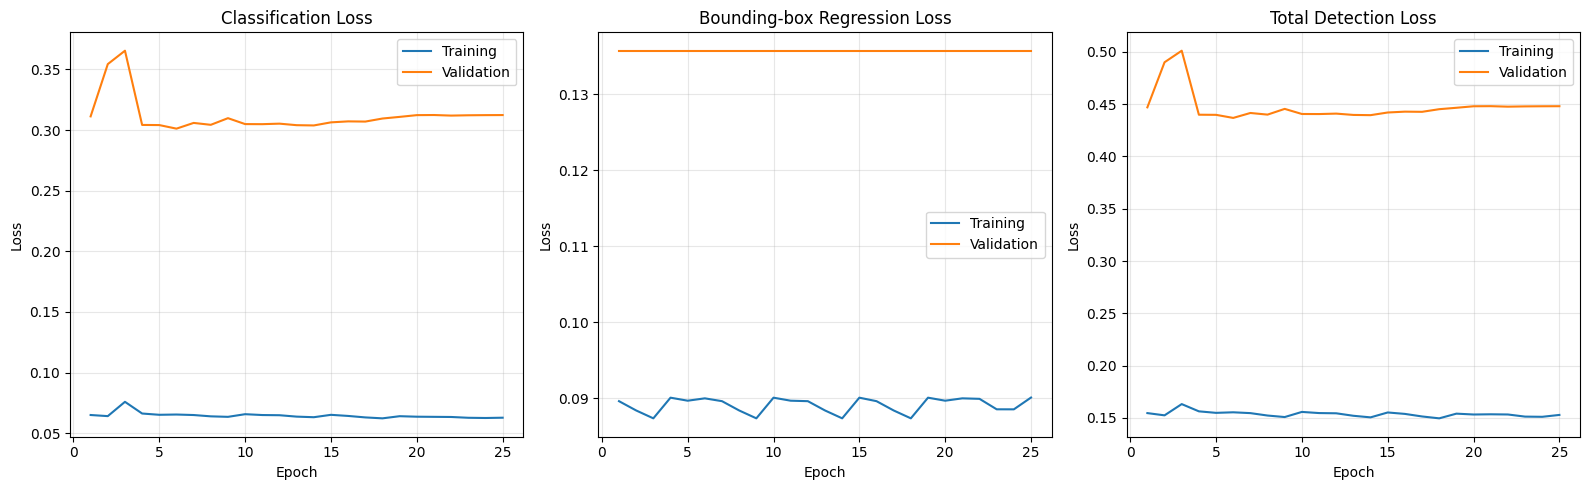

In [19]:
fig, axes = plt.subplots(
    1,
    3,
    figsize=(16, 5),
)

loss_pairs = [
    (
        "train/classification_loss",
        "val/classification_loss",
        "Classification Loss",
    ),
    (
        "train/bbox_regression_loss",
        "val/bbox_regression_loss",
        "Bounding-box Regression Loss",
    ),
    (
        "train/total_loss",
        "val/total_loss",
        "Total Detection Loss",
    ),
]

for ax, (
    train_col,
    val_col,
    title,
) in zip(
    axes,
    loss_pairs,
):
    ax.plot(
        history_df["epoch"],
        history_df[train_col],
        label="Training",
    )

    ax.plot(
        history_df["epoch"],
        history_df[val_col],
        label="Validation",
    )

    ax.set_title(title)
    ax.set_xlabel("Epoch")
    ax.set_ylabel("Loss")
    ax.grid(alpha=0.3)
    ax.legend()

plt.tight_layout()

plt.savefig(
    PLOTS_DIR
    / "training_validation_loss_curves.png",
    dpi=300,
    bbox_inches="tight",
)

plt.show()

## 17. Training vs validation mAP@50-95 vs epoch


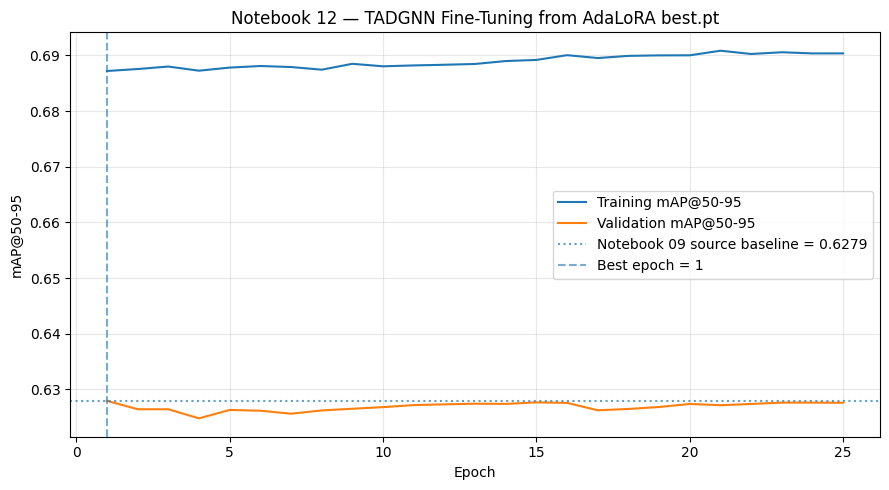

In [20]:
plt.figure(
    figsize=(9, 5)
)

plt.plot(
    history_df["epoch"],
    history_df["train/mAP50-95"],
    label="Training mAP@50-95",
)

plt.plot(
    history_df["epoch"],
    history_df["val/mAP50-95"],
    label="Validation mAP@50-95",
)

if np.isfinite(source_baseline_map):
    plt.axhline(
        source_baseline_map,
        linestyle=":",
        alpha=0.7,
        label=f"Notebook 09 source baseline = {source_baseline_map:.4f}",
    )

plt.axvline(
    best_epoch,
    linestyle="--",
    alpha=0.6,
    label=f"Best epoch = {best_epoch}",
)

plt.xlabel("Epoch")
plt.ylabel("mAP@50-95")

plt.title(
    "Notebook 12 — TADGNN Fine-Tuning from AdaLoRA best.pt"
)

plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()

plt.savefig(
    PLOTS_DIR
    / "train_val_map50_95_vs_epoch.png",
    dpi=300,
    bbox_inches="tight",
)

plt.show()


## 18. Load the best model for final test evaluation

In [21]:
best_checkpoint = torch.load(
    BEST_PT,
    map_location="cpu",
    weights_only=False,
)

model.load_state_dict(
    best_checkpoint["model_state"]
)

model = model.to(DEVICE)
model.eval()

gc.collect()
torch.cuda.empty_cache()

print(
    f"Loaded best model from epoch "
    f"{best_checkpoint['epoch']} "
    f"(val mAP50-95="
    f"{best_checkpoint['best_map50_95']:.4f})"
)

Loaded best model from epoch 1 (val mAP50-95=0.6280)


## 19. Collect test predictions once

In [22]:
@torch.no_grad()
def collect_predictions(
    model,
    loader,
):
    model.eval()

    predictions = []
    targets_all = []
    paths_all = []

    total_forward_seconds = 0.0
    total_images = 0

    for images, targets, paths in loader:
        images_gpu = [
            img.to(
                DEVICE,
                non_blocking=True,
            )
            for img in images
        ]

        torch.cuda.synchronize()
        start = time.perf_counter()

        with autocast_context():
            outputs = model(
                images_gpu
            )

        torch.cuda.synchronize()

        total_forward_seconds += (
            time.perf_counter()
            - start
        )

        total_images += len(images)

        for out in outputs:
            predictions.append({
                "boxes":
                    out["boxes"].detach().cpu(),

                "scores":
                    out["scores"].detach().cpu(),

                "labels":
                    out["labels"].detach().cpu(),
            })

        for target in targets:
            targets_all.append({
                "boxes":
                    target["boxes"].detach().cpu(),

                "labels":
                    target["labels"].detach().cpu(),
            })

        paths_all.extend(paths)

    inference_ms = (
        total_forward_seconds
        / max(total_images, 1)
        * 1000
    )

    return (
        predictions,
        targets_all,
        paths_all,
        inference_ms,
    )


(
    test_predictions,
    test_targets,
    test_paths,
    inference_ms,
) = collect_predictions(
    model,
    test_loader,
)

fps = (
    1000 / inference_ms
    if inference_ms > 0
    else np.nan
)

print(
    "Test images:",
    len(test_predictions),
)

print(
    f"Model forward time: "
    f"{inference_ms:.3f} ms/image"
)

print(
    f"FPS: {fps:.2f}"
)

Test images: 949
Model forward time: 36.028 ms/image
FPS: 27.76


## 20. Test mAP50, mAP75 and mAP50–95

In [23]:
map_metric = MeanAveragePrecision(
    box_format="xyxy",
    iou_type="bbox",
    class_metrics=True,
)

map50_metric = MeanAveragePrecision(
    box_format="xyxy",
    iou_type="bbox",
    iou_thresholds=[0.50],
    class_metrics=True,
)

map_metric.update(
    test_predictions,
    test_targets,
)

map50_metric.update(
    test_predictions,
    test_targets,
)

map_result = (
    map_metric.compute()
)

map50_result = (
    map50_metric.compute()
)

test_map50 = float(
    map_result["map_50"]
)

test_map75 = float(
    map_result["map_75"]
)

test_map50_95 = float(
    map_result["map"]
)

print(
    f"mAP@50    : "
    f"{test_map50:.4f}"
)

print(
    f"mAP@75    : "
    f"{test_map75:.4f}"
)

print(
    f"mAP@50-95 : "
    f"{test_map50_95:.4f}"
)

mAP@50    : 0.9081
mAP@75    : 0.6207
mAP@50-95 : 0.6062


## 21. Precision, Recall, F1, matched box IoU and Dice

In [24]:
def class_aware_matches(
    pred,
    gt,
    conf_threshold=0.25,
    iou_threshold=0.50,
):
    keep = (
        pred["scores"]
        >= conf_threshold
    )

    p_boxes = pred["boxes"][keep]
    p_labels = pred["labels"][keep]

    g_boxes = gt["boxes"]
    g_labels = gt["labels"]

    if (
        len(p_boxes) == 0
        or len(g_boxes) == 0
    ):
        return (
            [],
            p_boxes,
            p_labels,
        )

    ious = box_iou(
        p_boxes,
        g_boxes,
    )

    candidates = []

    for pi in range(
        len(p_boxes)
    ):
        for gi in range(
            len(g_boxes)
        ):
            if (
                int(p_labels[pi])
                != int(g_labels[gi])
            ):
                continue

            iou = float(
                ious[pi, gi]
            )

            if (
                iou
                >= iou_threshold
            ):
                candidates.append(
                    (
                        iou,
                        pi,
                        gi,
                    )
                )

    candidates.sort(
        reverse=True
    )

    used_pred = set()
    used_gt = set()
    matches = []

    for iou, pi, gi in candidates:
        if (
            pi in used_pred
            or gi in used_gt
        ):
            continue

        used_pred.add(pi)
        used_gt.add(gi)

        matches.append(
            (
                pi,
                gi,
                iou,
            )
        )

    return (
        matches,
        p_boxes,
        p_labels,
    )


overall_tp = 0
overall_fp = 0
overall_fn = 0

matched_ious = []

per_class_counts = defaultdict(
    lambda: {
        "tp": 0,
        "fp": 0,
        "fn": 0,
        "ious": [],
    }
)

for pred, gt in zip(
    test_predictions,
    test_targets,
):
    (
        matches,
        p_boxes,
        p_labels,
    ) = class_aware_matches(
        pred,
        gt,
        CONF_THRESHOLD,
        MATCH_IOU_THRESHOLD,
    )

    matched_p = {
        m[0]
        for m in matches
    }

    matched_g = {
        m[1]
        for m in matches
    }

    tp = len(matches)
    fp = len(p_boxes) - tp
    fn = len(gt["boxes"]) - tp

    overall_tp += tp
    overall_fp += fp
    overall_fn += fn

    for (
        pi,
        gi,
        iou,
    ) in matches:
        cls_id = int(
            gt["labels"][gi]
        )

        matched_ious.append(
            iou
        )

        per_class_counts[
            cls_id
        ]["tp"] += 1

        per_class_counts[
            cls_id
        ]["ious"].append(
            iou
        )

    for pi, cls_id in enumerate(
        p_labels.tolist()
    ):
        if pi not in matched_p:
            per_class_counts[
                int(cls_id)
            ]["fp"] += 1

    for gi, cls_id in enumerate(
        gt["labels"].tolist()
    ):
        if gi not in matched_g:
            per_class_counts[
                int(cls_id)
            ]["fn"] += 1


test_precision = (
    overall_tp
    / (overall_tp + overall_fp)
    if (
        overall_tp + overall_fp
    )
    else 0.0
)

test_recall = (
    overall_tp
    / (overall_tp + overall_fn)
    if (
        overall_tp + overall_fn
    )
    else 0.0
)

test_f1 = (
    2
    * test_precision
    * test_recall
    / (
        test_precision
        + test_recall
    )
    if (
        test_precision
        + test_recall
    )
    else 0.0
)

mean_iou = (
    float(
        np.mean(matched_ious)
    )
    if matched_ious
    else np.nan
)

matched_dices = [
    2 * iou / (1 + iou)
    for iou in matched_ious
]

mean_dice = (
    float(
        np.mean(matched_dices)
    )
    if matched_dices
    else np.nan
)

print(
    f"Precision : "
    f"{test_precision:.4f}"
)

print(
    f"Recall    : "
    f"{test_recall:.4f}"
)

print(
    f"F1        : "
    f"{test_f1:.4f}"
)

print(
    f"TP / FP / FN: "
    f"{overall_tp} / "
    f"{overall_fp} / "
    f"{overall_fn}"
)

print(
    f"Mean matched box IoU : "
    f"{mean_iou:.4f}"
)

print(
    f"Mean matched box Dice: "
    f"{mean_dice:.4f}"
)

Precision : 0.7262
Recall    : 0.9288
F1        : 0.8151
TP / FP / FN: 1395 / 526 / 107
Mean matched box IoU : 0.8271
Mean matched box Dice: 0.9014


## 22. Per-class test performance

In [25]:
map95_by_class = {}
map50_by_class = {}

classes95 = (
    map_result["classes"]
    .cpu()
    .numpy()
    .astype(int)
)

values95 = (
    map_result["map_per_class"]
    .cpu()
    .numpy()
)

for cls_id, value in zip(
    classes95,
    values95,
):
    map95_by_class[
        int(cls_id)
    ] = (
        float(value)
        if value >= 0
        else np.nan
    )

classes50 = (
    map50_result["classes"]
    .cpu()
    .numpy()
    .astype(int)
)

values50 = (
    map50_result["map_per_class"]
    .cpu()
    .numpy()
)

for cls_id, value in zip(
    classes50,
    values50,
):
    map50_by_class[
        int(cls_id)
    ] = (
        float(value)
        if value >= 0
        else np.nan
    )


class_image_counts = defaultdict(
    set
)

class_instance_counts = defaultdict(
    int
)

for image_idx, target in enumerate(
    test_targets
):
    for cls_id in target[
        "labels"
    ].tolist():
        class_image_counts[
            int(cls_id)
        ].add(image_idx)

        class_instance_counts[
            int(cls_id)
        ] += 1


rows = []

for cls_id, class_name in enumerate(
    CLASS_NAMES
):
    stats = per_class_counts[
        cls_id
    ]

    tp = stats["tp"]
    fp = stats["fp"]
    fn = stats["fn"]

    p = (
        tp / (tp + fp)
        if tp + fp
        else np.nan
    )

    r = (
        tp / (tp + fn)
        if tp + fn
        else np.nan
    )

    f1 = (
        2 * p * r / (p + r)
        if (
            np.isfinite(p)
            and np.isfinite(r)
            and p + r > 0
        )
        else np.nan
    )

    cls_iou = (
        float(
            np.mean(
                stats["ious"]
            )
        )
        if stats["ious"]
        else np.nan
    )

    cls_dice = (
        2
        * cls_iou
        / (1 + cls_iou)
        if np.isfinite(
            cls_iou
        )
        else np.nan
    )

    rows.append({
        "Class": class_name,
        "Images":
            len(
                class_image_counts[
                    cls_id
                ]
            ),
        "Instances":
            class_instance_counts[
                cls_id
            ],
        "Box-P": p,
        "Box-R": r,
        "Box-F1": f1,
        "mAP50":
            map50_by_class.get(
                cls_id,
                np.nan,
            ),
        "mAP50-95":
            map95_by_class.get(
                cls_id,
                np.nan,
            ),
        "Mean Box IoU":
            cls_iou,
        "Mean Box Dice":
            cls_dice,
    })


per_class_df = pd.DataFrame(
    rows
).round(4)

per_class_df.to_csv(
    METRICS_DIR
    / "final_per_class_summary.csv",
    index=False,
)

display(per_class_df)

,Class,Images,Instances,Box-P,Box-R,Box-F1,mAP50,mAP50-95,Mean Box IoU,Mean Box Dice
0,finger,187,385,0.8023,0.8961,0.8466,0.9069,0.4580,0.7669,0.8681
1,crack,185,231,0.4817,0.8528,0.6156,0.7389,0.4307,0.7926,0.8843
2,black_core,150,152,0.9018,0.9671,0.9333,0.9745,0.9014,0.9470,0.9728
3,thick_line,149,167,0.7236,0.8623,0.7869,0.8515,0.4430,0.7677,0.8686
4,horizontal_dislocation,119,357,1.0000,1.0000,1.0000,1.0000,0.6563,0.8420,0.9142
5,short_circuit,113,113,0.9244,0.9735,0.9483,0.9553,0.9432,0.9740,0.9869
6,vertical_dislocation,16,64,0.3404,1.0000,0.5079,0.9631,0.5862,0.8174,0.8995
7,star_crack,30,33,0.5536,0.9394,0.6966,0.8749,0.4310,0.7513,0.8580
8,printing_error,0,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 23. Raw and normalized confusion matrices

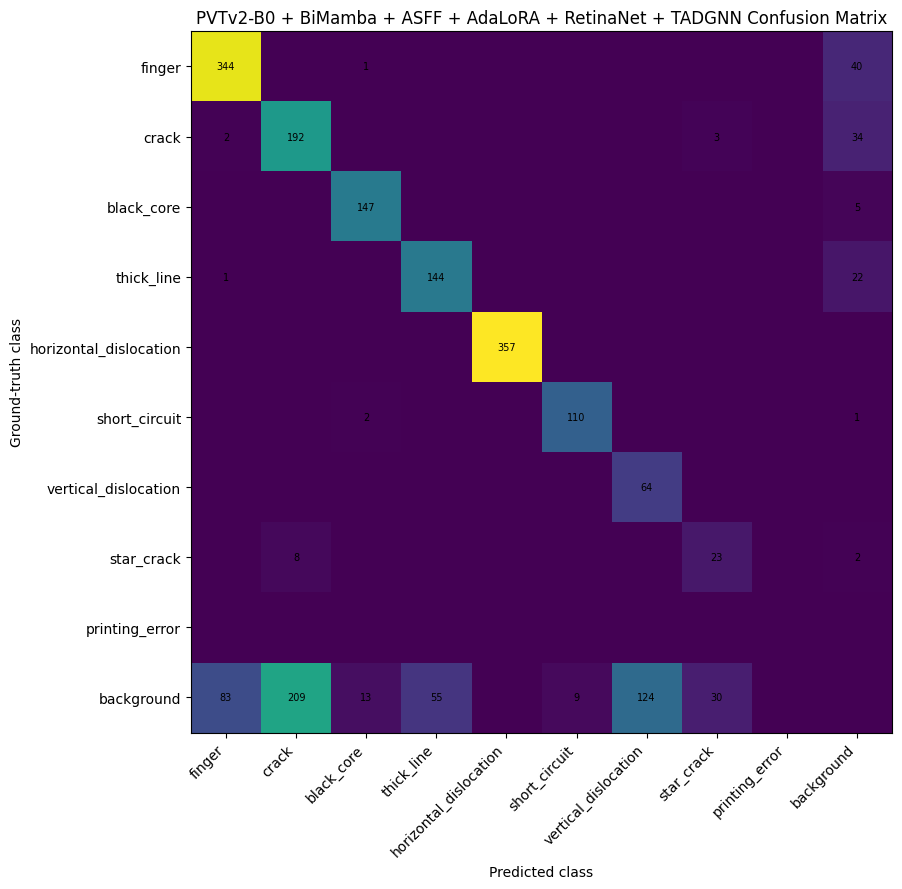

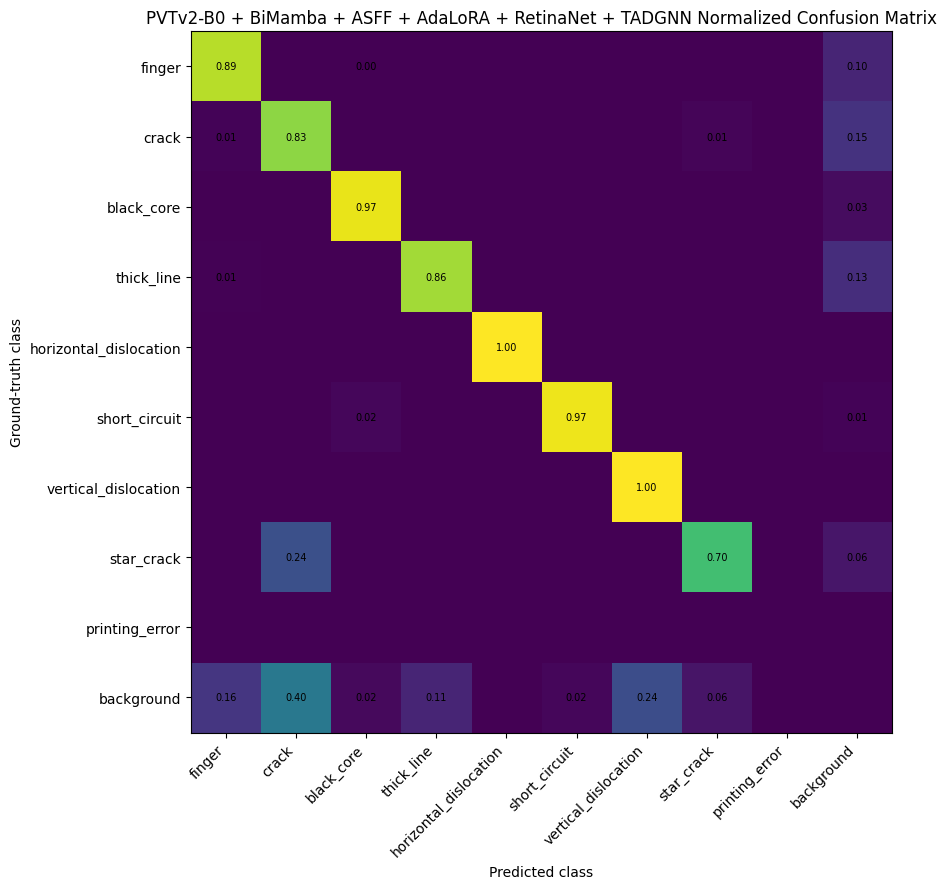

In [26]:
N = NUM_CLASSES
BG = N

confusion = np.zeros(
    (N + 1, N + 1),
    dtype=np.int64,
)

for pred, gt in zip(
    test_predictions,
    test_targets,
):
    keep = (
        pred["scores"]
        >= CONF_THRESHOLD
    )

    p_boxes = pred["boxes"][keep]
    p_labels = pred["labels"][keep]

    g_boxes = gt["boxes"]
    g_labels = gt["labels"]

    used_p = set()
    used_g = set()

    if (
        len(p_boxes)
        and len(g_boxes)
    ):
        ious = box_iou(
            p_boxes,
            g_boxes,
        )

        candidates = []

        for pi in range(
            len(p_boxes)
        ):
            for gi in range(
                len(g_boxes)
            ):
                iou = float(
                    ious[pi, gi]
                )

                if (
                    iou
                    >= MATCH_IOU_THRESHOLD
                ):
                    candidates.append(
                        (
                            iou,
                            pi,
                            gi,
                        )
                    )

        candidates.sort(
            reverse=True
        )

        for (
            iou,
            pi,
            gi,
        ) in candidates:
            if (
                pi in used_p
                or gi in used_g
            ):
                continue

            used_p.add(pi)
            used_g.add(gi)

            confusion[
                int(g_labels[gi]),
                int(p_labels[pi]),
            ] += 1

    for gi, cls_id in enumerate(
        g_labels.tolist()
    ):
        if gi not in used_g:
            confusion[
                int(cls_id),
                BG,
            ] += 1

    for pi, cls_id in enumerate(
        p_labels.tolist()
    ):
        if pi not in used_p:
            confusion[
                BG,
                int(cls_id),
            ] += 1


labels_cm = (
    CLASS_NAMES
    + ["background"]
)

row_sums = confusion.sum(
    axis=1,
    keepdims=True,
)

normalized = np.divide(
    confusion,
    row_sums,
    out=np.zeros_like(
        confusion,
        dtype=float,
    ),
    where=row_sums != 0,
)

pd.DataFrame(
    confusion,
    index=labels_cm,
    columns=labels_cm,
).to_csv(
    METRICS_DIR
    / "confusion_matrix.csv"
)

pd.DataFrame(
    normalized,
    index=labels_cm,
    columns=labels_cm,
).to_csv(
    METRICS_DIR
    / "confusion_matrix_normalized.csv"
)


def plot_confusion(
    matrix,
    title,
    filename,
    fmt,
):
    fig, ax = plt.subplots(
        figsize=(11, 9)
    )

    ax.imshow(matrix)

    ax.set_xticks(
        range(len(labels_cm))
    )

    ax.set_yticks(
        range(len(labels_cm))
    )

    ax.set_xticklabels(
        labels_cm,
        rotation=45,
        ha="right",
    )

    ax.set_yticklabels(
        labels_cm
    )

    ax.set_xlabel(
        "Predicted class"
    )

    ax.set_ylabel(
        "Ground-truth class"
    )

    ax.set_title(title)

    for i in range(
        matrix.shape[0]
    ):
        for j in range(
            matrix.shape[1]
        ):
            value = matrix[i, j]

            text = (
                f"{value:.2f}"
                if fmt == "float"
                else str(int(value))
            )

            if value != 0:
                ax.text(
                    j,
                    i,
                    text,
                    ha="center",
                    va="center",
                    fontsize=7,
                )

    plt.tight_layout()

    plt.savefig(
        PLOTS_DIR / filename,
        dpi=300,
        bbox_inches="tight",
    )

    plt.show()


plot_confusion(
    confusion,
    "PVTv2-B0 + BiMamba + ASFF + AdaLoRA + RetinaNet + TADGNN Confusion Matrix",
    "confusion_matrix.png",
    "int",
)

plot_confusion(
    normalized,
    "PVTv2-B0 + BiMamba + ASFF + AdaLoRA + RetinaNet + TADGNN Normalized Confusion Matrix",
    "confusion_matrix_normalized.png",
    "float",
)

## 24. Ground Truth vs Prediction

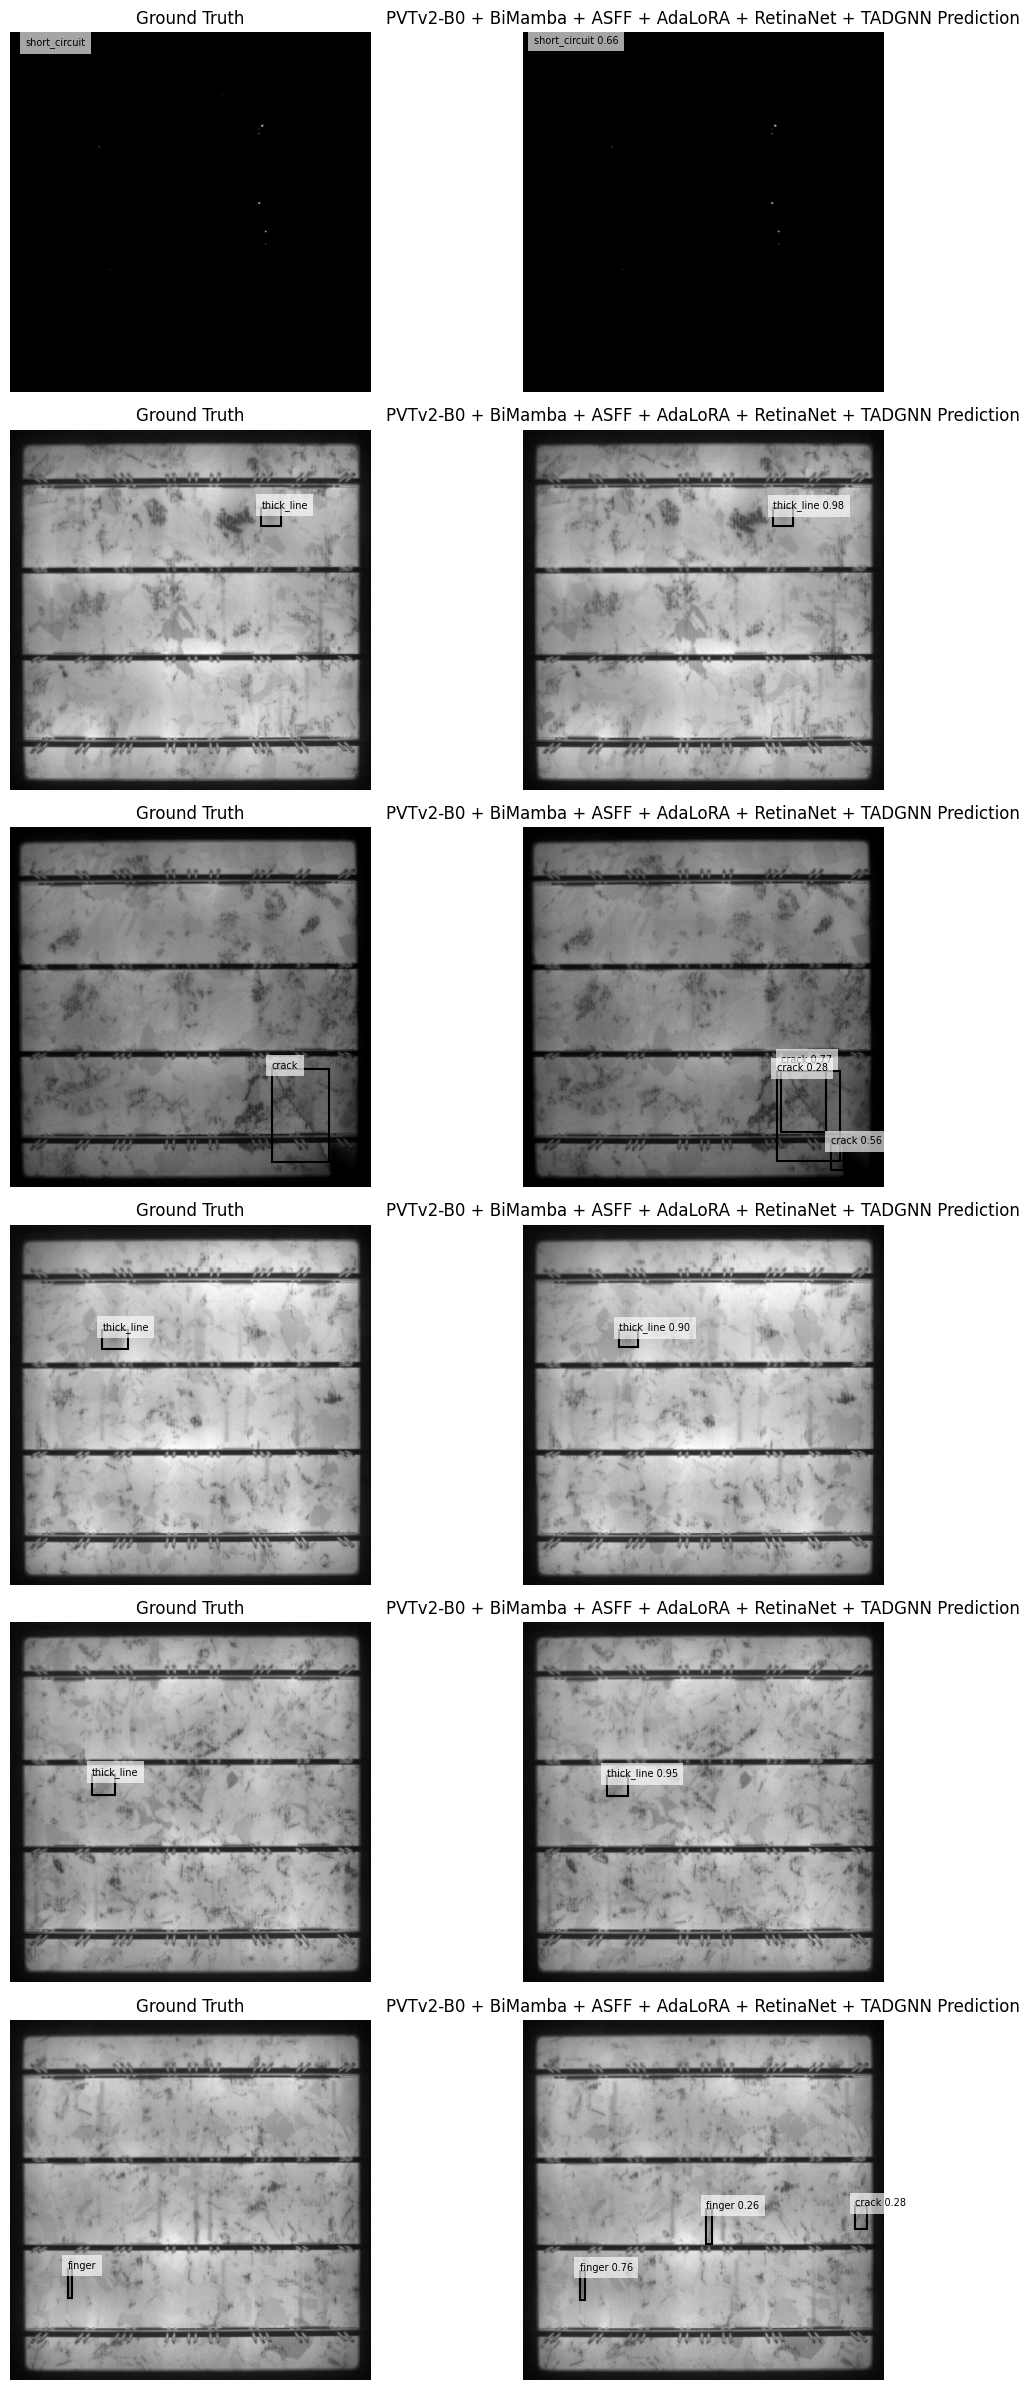

In [27]:
from matplotlib.patches import Rectangle

def show_box(
    ax,
    box,
    label,
    linewidth=1.5,
):
    x1, y1, x2, y2 = box

    rect = Rectangle(
        (x1, y1),
        x2 - x1,
        y2 - y1,
        fill=False,
        linewidth=linewidth,
    )

    ax.add_patch(rect)

    ax.text(
        x1,
        max(10, y1),
        label,
        fontsize=7,
        bbox=dict(
            facecolor="white",
            alpha=0.65,
            edgecolor="none",
        ),
    )


defect_indices = [
    i
    for i, target
    in enumerate(test_targets)
    if len(target["boxes"]) > 0
]

random.seed(SEED)

sample_indices = random.sample(
    defect_indices,
    min(
        6,
        len(defect_indices),
    ),
)

fig, axes = plt.subplots(
    len(sample_indices),
    2,
    figsize=(
        12,
        4 * len(sample_indices),
    ),
)

if len(sample_indices) == 1:
    axes = np.array([axes])

for row, idx in enumerate(
    sample_indices
):
    image_tensor, gt, _ = (
        test_dataset[idx]
    )

    image_np = (
        image_tensor
        .permute(1, 2, 0)
        .numpy()
        .clip(0, 1)
    )

    pred = test_predictions[idx]

    axes[row, 0].imshow(
        image_np
    )

    for box, cls_id in zip(
        gt["boxes"].numpy(),
        gt["labels"].numpy(),
    ):
        show_box(
            axes[row, 0],
            box,
            CLASS_NAMES[
                int(cls_id)
            ],
        )

    axes[row, 0].set_title(
        "Ground Truth"
    )

    axes[row, 0].axis("off")

    axes[row, 1].imshow(
        image_np
    )

    keep = (
        pred["scores"]
        >= CONF_THRESHOLD
    )

    for (
        box,
        cls_id,
        score,
    ) in zip(
        pred["boxes"][keep].numpy(),
        pred["labels"][keep].numpy(),
        pred["scores"][keep].numpy(),
    ):
        show_box(
            axes[row, 1],
            box,
            (
                f"{CLASS_NAMES[int(cls_id)]} "
                f"{score:.2f}"
            ),
        )

    axes[row, 1].set_title(
        "PVTv2-B0 + BiMamba + ASFF + AdaLoRA + RetinaNet + TADGNN Prediction"
    )

    axes[row, 1].axis("off")

plt.tight_layout()

plt.savefig(
    PLOTS_DIR
    / "ground_truth_vs_prediction.png",
    dpi=300,
    bbox_inches="tight",
)

plt.show()

## 25. Model complexity and parameter efficiency


In [28]:
total_params = sum(
    p.numel()
    for p in model.parameters()
)

trainable_params = sum(
    p.numel()
    for p in model.parameters()
    if p.requires_grad
)

mamba_params = sum(
    p.numel()
    for p
    in model.backbone
    .deep_mamba
    .parameters()
)

asff_params = sum(
    p.numel()
    for p
    in model.backbone
    .asff
    .parameters()
)

tadgnn_params = sum(
    p.numel()
    for p
    in model.tadgnn
    .parameters()
)

fpn_head_params = sum(
    p.numel()
    for p
    in fpn_head_params_list
)

# AdaLoRA source adapters are frozen in Notebook 12, so count them
# independent of requires_grad.
adalora_params_count = sum(
    p.numel()
    for name, p
    in model.named_parameters()
    if "lora_" in name
)

source_detector_params = (
    total_params
    - tadgnn_params
)

if trainable_params != tadgnn_params:
    raise RuntimeError(
        "Final trainable count is not exactly TADGNN."
    )

final_rank_stats = (
    adalora_rank_stats()
)

model_size_mb = (
    BEST_PT.stat().st_size
    / 1024**2
    if BEST_PT.exists()
    else np.nan
)

model_info_df = pd.DataFrame([{
    "model":
        "PVTv2-B0 + BiMamba + FPN + ASFF + AdaLoRA + RetinaNet + TADGNN",

    "source_checkpoint":
        str(
            SOURCE_BEST_PT
        ),

    "source_detector_frozen":
        True,

    "parameters":
        total_params,

    "parameters_M":
        total_params / 1e6,

    "trainable_parameters":
        trainable_params,

    "trainable_parameters_M":
        trainable_params / 1e6,

    "trainable_percent":
        (
            100.0
            * trainable_params
            / total_params
        ),

    "source_detector_parameters":
        source_detector_params,

    "source_detector_parameters_M":
        source_detector_params
        / 1e6,

    "mamba_parameters":
        mamba_params,

    "mamba_parameters_M":
        mamba_params / 1e6,

    "asff_parameters":
        asff_params,

    "asff_parameters_M":
        asff_params / 1e6,

    "tadgnn_parameters":
        tadgnn_params,

    "tadgnn_parameters_M":
        tadgnn_params / 1e6,

    "tadgnn_top_k":
        TADGNN_TOP_K,

    "tadgnn_k_neighbors":
        TADGNN_K_NEIGHBORS,

    "tadgnn_layers":
        TADGNN_NUM_LAYERS,

    "tadgnn_heads":
        TADGNN_NUM_HEADS,

    "tadgnn_residual_gate":
        float(
            torch.tanh(
                model.tadgnn
                .gate.detach()
            )
            .cpu()
        ),

    "fpn_head_parameters":
        fpn_head_params,

    "fpn_head_parameters_M":
        fpn_head_params / 1e6,

    "adalora_target_modules":
        len(
            targeted_module_names
        ),

    "adalora_parameters":
        adalora_params_count,

    "adalora_parameters_M":
        adalora_params_count
        / 1e6,

    "adalora_trainable_in_notebook12":
        0,

    "adalora_init_rank":
        ADALORA_INIT_R,

    "adalora_target_rank":
        ADALORA_TARGET_R,

    "final_active_rank_mean":
        final_rank_stats[
            "active_rank_mean"
        ],

    "final_active_rank_total":
        final_rank_stats[
            "active_rank_total"
        ],

    "best_checkpoint_size_MB":
        model_size_mb,
}]).round(4)

model_info_df.to_csv(
    METRICS_DIR
    / "model_info.csv",
    index=False,
)

display(
    model_info_df
)


,model,source_checkpoint,source_detector_frozen,parameters,parameters_M,trainable_parameters,trainable_parameters_M,trainable_percent,source_detector_parameters,source_detector_parameters_M,...,fpn_head_parameters_M,adalora_target_modules,adalora_parameters,adalora_parameters_M,adalora_trainable_in_notebook12,adalora_init_rank,adalora_target_rank,final_active_rank_mean,final_active_rank_total,best_checkpoint_size_MB
0,PVTv2-B0 + BiMamba + FPN + ASFF + AdaLoRA + Re...,/content/drive/MyDrive/Study Materials /CSE465...,True,15069660,15.0697,1140434,1.1404,7.5677,13929226,13.9292,...,8.0644,40,227808,0.2278,0,12,8,9.2,368,57.6173


# 26. Final model summary

In [29]:
history_df = pd.read_csv(
    METRICS_DIR
    / "training_history.csv"
)

epochs_completed = int(
    history_df[
        "epoch"
    ].max()
)

best_checkpoint_meta = torch.load(
    BEST_PT,
    map_location="cpu",
    weights_only=False,
)

best_epoch = int(
    best_checkpoint_meta.get(
        "epoch",
        history_df.loc[
            history_df[
                "val/mAP50-95"
            ].idxmax(),
            "epoch",
        ],
    )
)

best_val_map = float(
    best_checkpoint_meta.get(
        "best_map50_95",
        np.nan,
    )
)

final_rank_stats = (
    adalora_rank_stats()
)

final_summary_df = pd.DataFrame([{
    "Model":
        "PVTv2-B0 + BiMamba + FPN + ASFF + AdaLoRA + RetinaNet + TADGNN",

    "Experiment":
        "A4_Aug_Mamba_ASFF_AdaLoRA_TADGNN_From_AdaLoRA_BestPT",

    "Source Checkpoint":
        str(
            SOURCE_BEST_PT
        ),

    "Source Checkpoint Epoch":
        source_epoch,

    "Source Baseline Val mAP@50-95":
        source_baseline_map,

    "Optimization Scope":
        "TADGNN only",

    "Epochs Completed":
        epochs_completed,

    "Best Epoch":
        best_epoch,

    "Best Val mAP@50-95":
        best_val_map,

    "Early Stopped":
        (
            epochs_completed
            < MAX_EPOCHS
        ),

    "Precision":
        test_precision,

    "Recall":
        test_recall,

    "F1":
        test_f1,

    "mAP@50":
        test_map50,

    "mAP@75":
        test_map75,

    "mAP@50-95":
        test_map50_95,

    "Mean Box IoU":
        mean_iou,

    "Mean Box Dice":
        mean_dice,

    "Matched Boxes":
        len(
            matched_ious
        ),

    "Parameters (M)":
        total_params
        / 1e6,

    "Trainable Parameters (M)":
        trainable_params
        / 1e6,

    "Trainable Parameters (%)":
        (
            100.0
            * trainable_params
            / total_params
        ),

    "Mamba Parameters (M)":
        mamba_params
        / 1e6,

    "ASFF Parameters (M)":
        asff_params
        / 1e6,

    "TADGNN Parameters (M)":
        tadgnn_params
        / 1e6,

    "TADGNN Top-K":
        TADGNN_TOP_K,

    "TADGNN k-Neighbors":
        TADGNN_K_NEIGHBORS,

    "TADGNN Layers":
        TADGNN_NUM_LAYERS,

    "TADGNN Heads":
        TADGNN_NUM_HEADS,

    "TADGNN Residual Gate":
        float(
            torch.tanh(
                model.tadgnn
                .gate.detach()
            )
            .cpu()
        ),

    "TADGNN Edge-Change Fraction":
        float(
            model.tadgnn
            .last_edge_change
            .detach()
            .cpu()
        )
        if (
            model.tadgnn
            .last_edge_change
            is not None
        )
        else np.nan,

    "FPN/Head Parameters (M)":
        fpn_head_params
        / 1e6,

    "AdaLoRA Target Modules":
        len(
            targeted_module_names
        ),

    "AdaLoRA Parameters (M)":
        adalora_params_count
        / 1e6,

    "AdaLoRA Init Rank":
        ADALORA_INIT_R,

    "AdaLoRA Target Rank":
        ADALORA_TARGET_R,

    "Final Active Rank Mean":
        final_rank_stats[
            "active_rank_mean"
        ],

    "Final Active Rank Total":
        final_rank_stats[
            "active_rank_total"
        ],

    "Model Size (MB)":
        model_size_mb,

    "Physical Batch":
        BATCH_SIZE,

    "Gradient Accumulation":
        ACCUM_STEPS,

    "Effective Batch":
        EFFECTIVE_BATCH,

    "Mean Train Time/Epoch (min)":
        history_df[
            "train_seconds"
        ].mean() / 60,

    "Mean Val-Loss Time/Epoch (min)":
        history_df[
            "val_loss_seconds"
        ].mean() / 60,

    "Mean Val-mAP Time/Epoch (min)":
        history_df[
            "val_map_seconds"
        ].mean() / 60,

    "Mean Total Time/Epoch (min)":
        history_df[
            "total_seconds"
        ].mean() / 60,

    "Total Training Run Time (min)":
        history_df[
            "total_seconds"
        ].sum() / 60,

    "Peak VRAM (GB)":
        history_df[
            "peak_vram_GB"
        ].max(),

    "Inference (ms/image)":
        inference_ms,

    "FPS":
        fps,
}]).round(4)

print("=" * 82)

print(
    "PVTv2-B0 + MAMBA + ASFF + AdaLoRA + RETINANET + TADGNN AUGMENTED "
    "(FROM NOTEBOOK 09 best.pt; TADGNN-ONLY FINE-TUNING) — FINAL MODEL SUMMARY"
)

print("=" * 82)

display(
    final_summary_df
)

print(
    "\nPER-CLASS TEST PERFORMANCE"
)

display(
    per_class_df
)

final_summary_df.to_csv(
    METRICS_DIR
    / "final_model_summary.csv",
    index=False,
)

print("\nSaved:")

print(
    METRICS_DIR
    / "final_model_summary.csv"
)

print(
    METRICS_DIR
    / "final_per_class_summary.csv"
)


PVTv2-B0 + MAMBA + ASFF + AdaLoRA + RETINANET + TADGNN AUGMENTED (FROM NOTEBOOK 09 best.pt; TADGNN-ONLY FINE-TUNING) — FINAL MODEL SUMMARY


,Model,Experiment,Source Checkpoint,Source Checkpoint Epoch,Source Baseline Val mAP@50-95,Optimization Scope,Epochs Completed,Best Epoch,Best Val mAP@50-95,Early Stopped,...,Gradient Accumulation,Effective Batch,Mean Train Time/Epoch (min),Mean Val-Loss Time/Epoch (min),Mean Val-mAP Time/Epoch (min),Mean Total Time/Epoch (min),Total Training Run Time (min),Peak VRAM (GB),Inference (ms/image),FPS
0,PVTv2-B0 + BiMamba + FPN + ASFF + AdaLoRA + Re...,A4_Aug_Mamba_ASFF_AdaLoRA_TADGNN_From_AdaLoRA_...,/content/drive/MyDrive/Study Materials /CSE465...,8,0.6279,TADGNN only,25,1,0.628,False,...,2,16,3.7984,0.5279,0.577,7.5633,189.0826,0.7304,36.0282,27.756



PER-CLASS TEST PERFORMANCE


,Class,Images,Instances,Box-P,Box-R,Box-F1,mAP50,mAP50-95,Mean Box IoU,Mean Box Dice
0,finger,187,385,0.8023,0.8961,0.8466,0.9069,0.4580,0.7669,0.8681
1,crack,185,231,0.4817,0.8528,0.6156,0.7389,0.4307,0.7926,0.8843
2,black_core,150,152,0.9018,0.9671,0.9333,0.9745,0.9014,0.9470,0.9728
3,thick_line,149,167,0.7236,0.8623,0.7869,0.8515,0.4430,0.7677,0.8686
4,horizontal_dislocation,119,357,1.0000,1.0000,1.0000,1.0000,0.6563,0.8420,0.9142
5,short_circuit,113,113,0.9244,0.9735,0.9483,0.9553,0.9432,0.9740,0.9869
6,vertical_dislocation,16,64,0.3404,1.0000,0.5079,0.9631,0.5862,0.8174,0.8995
7,star_crack,30,33,0.5536,0.9394,0.6966,0.8749,0.4310,0.7513,0.8580
8,printing_error,0,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN



Saved:
/content/drive/MyDrive/Study Materials /CSE465/12_PVTv2B0_Mamba_ASFF_AdaLoRA_TADGNN_RetinaNet_Aug/metrics/final_model_summary.csv
/content/drive/MyDrive/Study Materials /CSE465/12_PVTv2B0_Mamba_ASFF_AdaLoRA_TADGNN_RetinaNet_Aug/metrics/final_per_class_summary.csv


## Revised graph ablation design

**No graph — Notebook 09 source**
- PVTv2-B0 + deep bidirectional Mamba + FPN + ASFF + RetinaNet
- canonical PEFT AdaLoRA
- Notebook 09 `best.pt`
- this is the exact source checkpoint used to initialize Notebook 12

**Static GBR — submitted paper**
- top-K anchor nodes
- fixed KNN / grid-band connectivity
- GAT-based logit correction

**TADGNN — Notebook 12**
- reconstructs the Notebook 09 AdaLoRA architecture
- loads every shared Notebook 09 state-dict tensor exactly
- freezes the transferred detector
- trains only the new TADGNN module
- topology is recomputed from learned feature/geometry affinity at every graph layer
- residual classification-logit refinement; box regression remains unchanged

This makes the revised graph experiment a controlled comparison of the graph reasoning stage rather than a second full detector retraining.


## 27. Revised graph ablation table

This cell creates the paper-ready comparison between:

- **No graph — Notebook 09 AdaLoRA**
- **Static GBR — submitted-paper result**
- **TADGNN — corrected Notebook 12**

The no-graph row is read from Notebook 09's actual `final_model_summary.csv` when available, because that is the exact checkpoint family used to initialize this TADGNN run. If the summary CSV is unavailable, the submitted-paper AdaLoRA values are used as a fallback.


In [30]:
# Submitted-paper fallback values.
no_graph_row = {
    "Configuration":
        "No graph (AdaLoRA)",
    "F1":
        0.8151,
    "mAP@50":
        0.9087,
    "mAP@50-95":
        0.6065,
    "Source":
        "Submitted paper ablation fallback",
}

static_gbr_row = {
    "Configuration":
        "Static GBR",
    "F1":
        0.8148,
    "mAP@50":
        0.9086,
    "mAP@50-95":
        0.6061,
    "Source":
        "Submitted paper ablation",
}

# Prefer the actual Notebook 09 summary because Notebook 09 best.pt
# is the exact detector source used by corrected Notebook 12.
notebook09_summary = (
    SOURCE_EXP_ROOT
    / "metrics"
    / "final_model_summary.csv"
)

if notebook09_summary.exists():
    notebook09_df = pd.read_csv(
        notebook09_summary
    )

    if len(
        notebook09_df
    ) > 0:
        row = (
            notebook09_df
            .iloc[0]
        )

        no_graph_row = {
            "Configuration":
                "No graph (Notebook 09 AdaLoRA)",
            "F1":
                float(
                    row["F1"]
                ),
            "mAP@50":
                float(
                    row["mAP@50"]
                ),
            "mAP@50-95":
                float(
                    row["mAP@50-95"]
                ),
            "Source":
                "Notebook 09 final_model_summary.csv",
        }

tadgnn_row = {
    "Configuration":
        "TADGNN (Notebook 12)",
    "F1":
        test_f1,
    "mAP@50":
        test_map50,
    "mAP@50-95":
        test_map50_95,
    "Source":
        "Notebook 12 from Notebook 09 best.pt; TADGNN-only fine-tuning",
}

graph_ablation_df = pd.DataFrame([
    no_graph_row,
    static_gbr_row,
    tadgnn_row,
]).round(4)

graph_ablation_df[
    "ΔmAP@50-95 vs No graph"
] = (
    graph_ablation_df[
        "mAP@50-95"
    ]
    - float(
        graph_ablation_df
        .iloc[0][
            "mAP@50-95"
        ]
    )
).round(4)

graph_ablation_df[
    "ΔmAP@50-95 vs Static GBR"
] = (
    graph_ablation_df[
        "mAP@50-95"
    ]
    - float(
        graph_ablation_df
        .iloc[1][
            "mAP@50-95"
        ]
    )
).round(4)

graph_ablation_path = (
    METRICS_DIR
    / "graph_ablation_comparison.csv"
)

graph_ablation_df.to_csv(
    graph_ablation_path,
    index=False,
)

display(
    graph_ablation_df
)

print(
    "Saved:",
    graph_ablation_path,
)


,Configuration,F1,mAP@50,mAP@50-95,Source,ΔmAP@50-95 vs No graph,ΔmAP@50-95 vs Static GBR
0,No graph (Notebook 09 AdaLoRA),0.8144,0.9086,0.6064,Notebook 09 final_model_summary.csv,0.0000,0.0003
1,Static GBR,0.8148,0.9086,0.6061,Submitted paper ablation,-0.0003,0.0000
2,TADGNN (Notebook 12),0.8151,0.9081,0.6062,Notebook 12 from Notebook 09 best.pt; TADGNN-o...,-0.0002,0.0001


Saved: /content/drive/MyDrive/Study Materials /CSE465/12_PVTv2B0_Mamba_ASFF_AdaLoRA_TADGNN_RetinaNet_Aug/metrics/graph_ablation_comparison.csv


## Final Drive checkpoint verification

Do **not disconnect Colab** until this cell confirms that the corrected Notebook 12 checkpoints, source-transfer verification, final summaries, and graph-ablation CSV are safely present in Google Drive.


In [31]:
print("=" * 72)
print("FINAL DRIVE PERSISTENCE CHECK — NOTEBOOK 12")
print("=" * 72)

files_to_verify = [
    BEST_PT,
    LAST_PT,
    METRICS_DIR
    / "source_transfer_validation.csv",
    METRICS_DIR
    / "final_model_summary.csv",
    METRICS_DIR
    / "final_per_class_summary.csv",
    METRICS_DIR
    / "graph_ablation_comparison.csv",
]

missing = []

for path in files_to_verify:
    exists = path.exists()

    if exists:
        size_mb = (
            path.stat().st_size
            / 1024**2
        )

        print(
            f"✅ {path.name:35s} "
            f"{size_mb:8.2f} MB"
        )
    else:
        print(
            f"❌ {path.name:35s} MISSING"
        )
        missing.append(
            str(path)
        )

if missing:
    raise RuntimeError(
        "Some final files are missing from Google Drive. "
        "Do NOT disconnect the runtime yet."
    )

print(
    "\n✅ All required corrected Notebook 12 TADGNN files are safely present in Google Drive."
)


FINAL DRIVE PERSISTENCE CHECK — NOTEBOOK 12
✅ best.pt                                57.62 MB
✅ last.pt                                66.43 MB
✅ source_transfer_validation.csv          0.00 MB
✅ final_model_summary.csv                 0.00 MB
✅ final_per_class_summary.csv             0.00 MB
✅ graph_ablation_comparison.csv           0.00 MB

✅ All required corrected Notebook 12 TADGNN files are safely present in Google Drive.
